# ML Assignment 1 — Activity recognition pipeline

This notebook goes from the raw phyphox zip files to two trained classifiers and the clinic cost analysis. Sections 1–4 build on the module starter notebook (Dr Seán Mullery, ATU, 2026).


## 0. Setup

My own recordings are in `Data/Dan_Data`. The five activity labels are the ones from the brief.

In [3]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OWN_DATA = Path("Data/Dan_Data")
LABELS = ["SIT", "STAND", "WALK", "UP", "DOWN"]

## 1. Reading a phyphox zip

These work like the starter's functions. I added two things:

- some phones export older column names (`Acceleration x (m/s^2)` instead of `X (m/s^2)`), so both are accepted,
- pooled files are in a folder for each person (`S03/UP_03.zip`), so the person's code can come from the folder name.

In [4]:
def read_sensor(zip_path, sensor="Accelerometer"):
    with zipfile.ZipFile(zip_path) as z:
        matches = []
        for name in z.namelist():
            file_name = Path(name).name.lower()
            if file_name == sensor.lower() + ".csv" and "__macosx" not in name.lower():
                matches.append(name)

        if len(matches) != 1:
            raise FileNotFoundError(f"Expected one {sensor}.csv in {zip_path}, found {len(matches)}")

        with z.open(matches[0]) as f:
            df = pd.read_csv(f)

    if sensor == "Accelerometer":
        new_names = ["X (m/s^2)", "Y (m/s^2)", "Z (m/s^2)"]
        old_names = ["Acceleration x (m/s^2)", "Acceleration y (m/s^2)", "Acceleration z (m/s^2)"]
    else:
        new_names = ["X (rad/s)", "Y (rad/s)", "Z (rad/s)"]
        old_names = ["Gyroscope x (rad/s)", "Gyroscope y (rad/s)", "Gyroscope z (rad/s)"]

    for old, new in zip(old_names, new_names):
        df = df.rename(columns={old: new})

    columns = ["Time (s)"] + new_names 
    for col in columns:
        if col not in df.columns:
            raise ValueError(f"Unexpected {sensor} columns: {list(df.columns)}")

    df = df[columns].copy()
    df.columns = ["t", "x", "y", "z"]   # time (s) and the three axes
    return df


def read_meta(zip_path, name="time"):
    with zipfile.ZipFile(zip_path) as z:
        matches = []
        for file_name in z.namelist():
            if file_name.lower().endswith(f"meta/{name}.csv") and "__macosx" not in file_name.lower():
                matches.append(file_name)

        if len(matches) == 0:
            raise FileNotFoundError(f"meta/{name}.csv not found in {zip_path}")

        with z.open(matches[0]) as f:
            return pd.read_csv(f)

`parse_name` splits a file name into the person, the activity and the recording number. It returns `None` if the name does not follow the pattern, like in the starter.

In [5]:
def parse_name(zip_path, root):
    parts = Path(zip_path).stem.split("_")

    if len(parts) == 2:
        folder = Path(zip_path).relative_to(root).parts[0]
        if folder[0] == "S" and folder[1:].isdigit():
            code = folder
        else:
            code = "Dan"
        parts = [code] + parts

    if len(parts) != 3:
        return None

    code, label, nn = parts
    label = label.upper()
    if label not in LABELS or not nn.isdigit():
        return None

    return {"participant": code, "label": label, "recording": Path(zip_path).name, "nn": int(nn)}


def find_zips(root):
    zips = []
    for path in Path(root).rglob("*.zip"):
        if "__macosx" not in str(path).lower():
            zips.append(path)
    return sorted(zips)

Try it on one of my walking recordings.

In [6]:
example = next(OWN_DATA.rglob("WALK_01.zip"))

acc = read_sensor(example, "Accelerometer")
gyro = read_sensor(example, "Gyroscope")
meta = read_meta(example, "time")

print(example.name, parse_name(example, OWN_DATA))
print(len(acc), "accelerometer readings and", len(gyro), "gyroscope readings")
acc.head()

WALK_01.zip {'participant': 'Dan', 'label': 'WALK', 'recording': 'WALK_01.zip', 'nn': 1}
3016 accelerometer readings and 3016 gyroscope readings


,t,x,y,z
0,0.006447,2.990332,-8.441995,3.700305
1,0.016394,2.982548,-8.320597,3.747158
2,0.026341,2.949017,-8.242160,3.840863
3,0.036289,2.893184,-8.203391,3.945346
4,0.046236,2.780767,-8.219707,3.992947


`meta/time.csv` has one START and one PAUSE, so this recording is one continuous run.

In [7]:
meta

,event,experiment time,system time,system time text
0,START,0.000000,1.792065e+09,2026-10-15 12:45:18.420 UTC+01:00
1,PAUSE,30.598644,1.792065e+09,2026-10-15 12:45:49.018 UTC+01:00


## 2. Looking at a recording

Always plot first. Acceleration includes gravity, so a still phone reads about 9.8 m/s² in total.

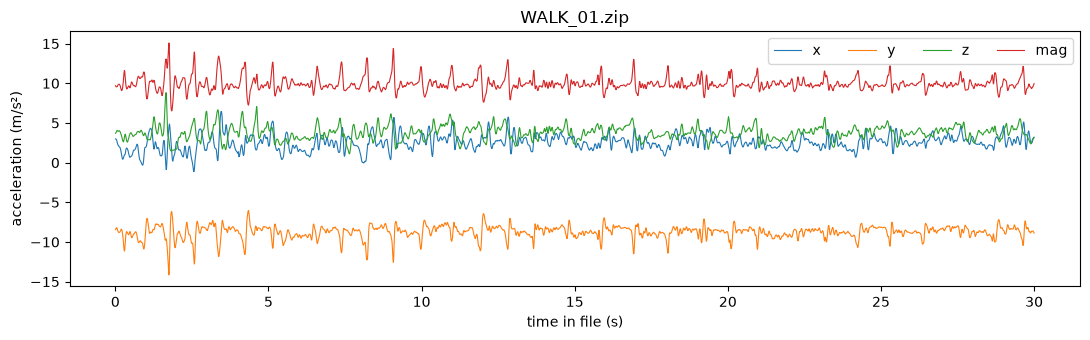

In [8]:
acc["mag"] = np.sqrt(acc.x**2 + acc.y**2 + acc.z**2)

fig, ax = plt.subplots(figsize=(11, 3.5))
for col in ["x", "y", "z", "mag"]:
    ax.plot(acc.t, acc[col], label=col, lw=0.8)

ax.set_xlabel("time in file (s)")
ax.set_ylabel("acceleration (m/s²)")
ax.set_title(example.name)
ax.legend(loc="upper right", ncol=4)
plt.tight_layout()
plt.show()

The first recording of each activity, for me and for one pooled person (S01). The start of each file shows the phone going into the pocket. The axes sit at different levels for the two of us because the phone is tilted differently in each pocket.

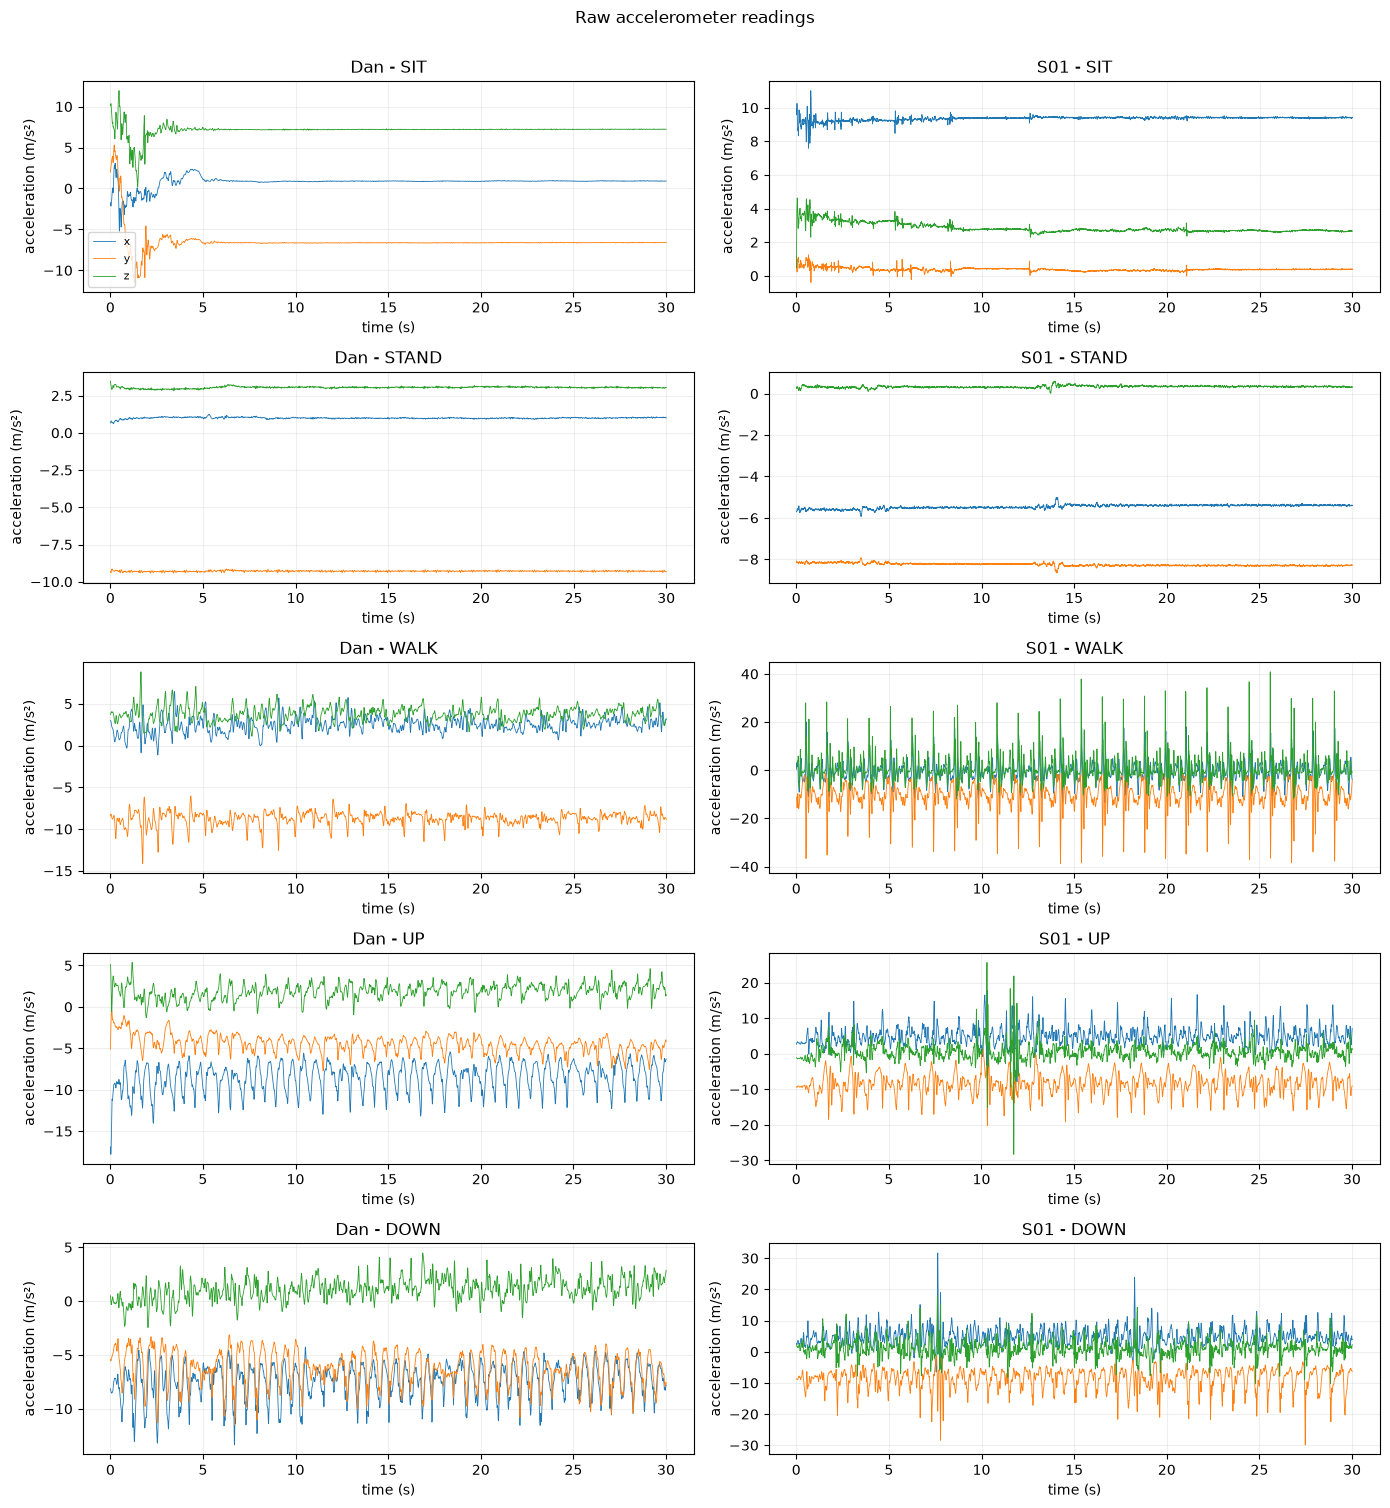

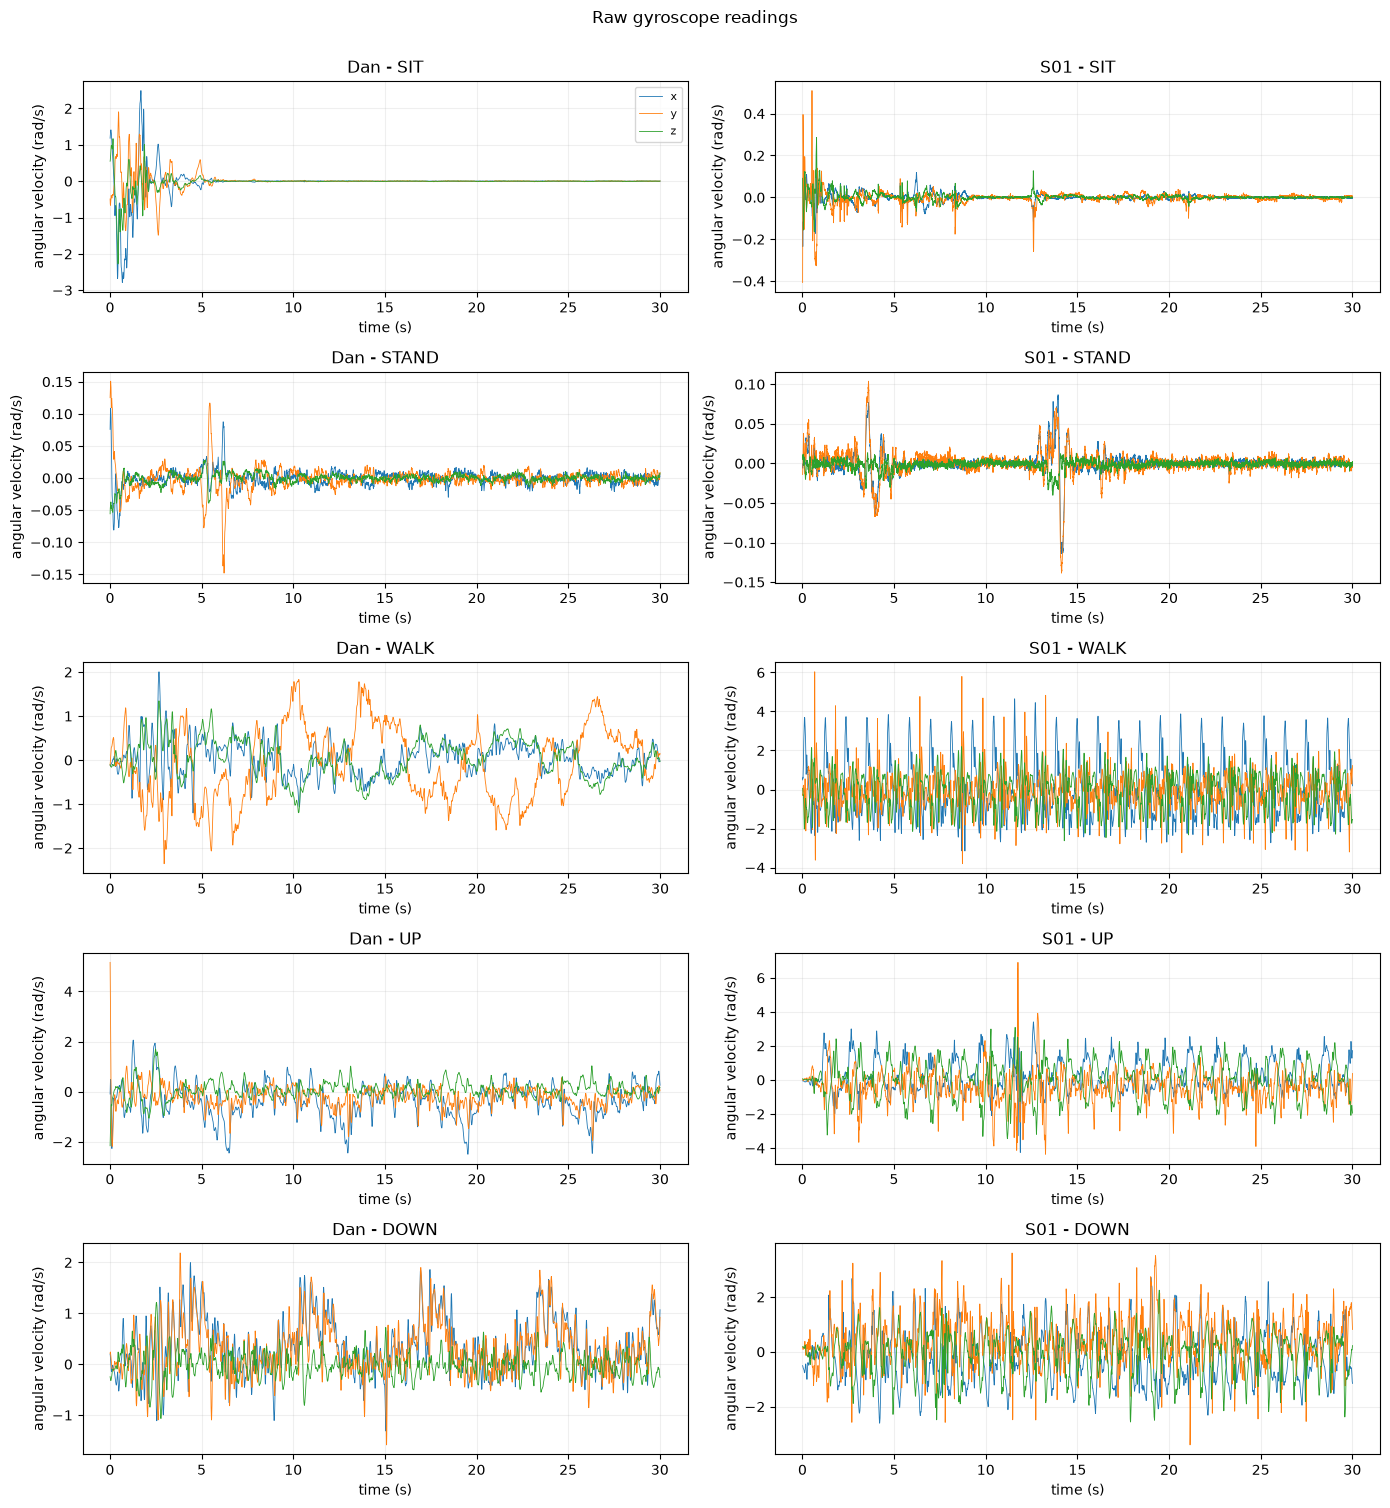

In [9]:
POOL_DATA = Path("Data/Pool Data")


def plot_raw_grid(sensor, unit):
    people = [("Dan", OWN_DATA), ("S01", POOL_DATA / "S01")]
    fig, axes = plt.subplots(5, 2, figsize=(14, 15))

    for col in range(len(people)):
        person, folder = people[col]

        for row in range(len(LABELS)):
            label = LABELS[row]
            zip_path = next(folder.rglob(f"{label}_01.zip"))
            df = read_sensor(zip_path, sensor)

            ax = axes[row, col]
            for axis in ["x", "y", "z"]:
                ax.plot(df.t, df[axis], lw=0.6, label=axis)
            ax.set_title(f"{person} - {label}")
            ax.set_xlabel("time (s)")
            ax.set_ylabel(unit)
            ax.grid(alpha=0.2)

    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"Raw {sensor.lower()} readings", y=1.002)
    plt.tight_layout()
    plt.show()


plot_raw_grid("Accelerometer", "acceleration (m/s²)")
plot_raw_grid("Gyroscope", "angular velocity (rad/s)")

## 3. Cleaning

Every rule here is applied by code to every file (mine and the pool).

### 3.1 Bad readings and lining up the two sensors

First, readings that are missing or infinite are removed, and so are repeated timestamps.

Second, the accelerometer and gyroscope never record at exactly the same moment, and different phones record at different rates. So each accelerometer reading is paired with the **nearest** gyroscope reading. A pair is only kept if the two readings are close enough in time (less than 0.75 × the usual gap between readings).

Finally, the magnitude of each sensor is added. It does not change with how the phone sits in the pocket.

In [10]:
def clean_sensor(df):
    out = df.replace([np.inf, -np.inf], np.nan)
    out = out.dropna()
    out = out.sort_values("t")
    out = out.drop_duplicates("t")
    out = out.reset_index(drop=True)

    removed = len(df) - len(out)
    return out, removed

In [11]:
def align_sensors(acc, gyro):
    acc, acc_removed = clean_sensor(acc)
    gyro, gyro_removed = clean_sensor(gyro)
    info = {"acc_removed": acc_removed, "gyro_removed": gyro_removed}

    if len(acc) < 2 or len(gyro) < 2:
        return pd.DataFrame(), info

    acc_gap = acc.t.diff().median()
    gyro_gap = gyro.t.diff().median()
    tolerance = 0.75 * max(acc_gap, gyro_gap)

    acc = acc.rename(columns={"x": "acc_x", "y": "acc_y", "z": "acc_z"})
    gyro = gyro.rename(columns={"t": "gyro_t", "x": "gyro_x", "y": "gyro_y", "z": "gyro_z"})

    both = pd.merge_asof(acc, gyro, left_on="t", right_on="gyro_t",
                         direction="nearest", tolerance=tolerance)

    info["unmatched_acc_rows"] = int(both.gyro_x.isna().sum())
    info["tolerance_ms"] = tolerance * 1000

    both = both.dropna(subset=["gyro_x", "gyro_y", "gyro_z"])
    both = both.drop(columns="gyro_t")

    both["acc_mag"] = np.sqrt(both.acc_x**2 + both.acc_y**2 + both.acc_z**2)
    both["gyro_mag"] = np.sqrt(both.gyro_x**2 + both.gyro_y**2 + both.gyro_z**2)

    return both.reset_index(drop=True), info

In [12]:
aligned, info = align_sensors(acc[["t", "x", "y", "z"]], gyro)

print(info)
aligned.head()

{'acc_removed': 0, 'gyro_removed': 0, 'unmatched_acc_rows': 0, 'tolerance_ms': np.float64(7.460999999999718)}


,t,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,acc_mag,gyro_mag
0,0.006447,2.990332,-8.441995,3.700305,-0.128378,-0.066356,-0.115412,9.690285,0.184943
1,0.016394,2.982548,-8.320597,3.747158,-0.128378,-0.066356,-0.115412,9.600475,0.184943
2,0.026341,2.949017,-8.242160,3.840863,-0.135354,-0.001517,-0.128652,9.559401,0.186746
3,0.036289,2.893184,-8.203391,3.945346,-0.115053,0.155632,-0.151494,9.551538,0.245782
4,0.046236,2.780767,-8.219707,3.992947,-0.115053,0.155632,-0.151494,9.551957,0.245782


**Timing evidence.** Different phones record at different rates. The table shows each person's rate for both sensors, from their `WALK_01` file.

In [13]:
people = [("Dan", OWN_DATA), ("S01", POOL_DATA / "S01"), ("S02", POOL_DATA / "S02"),
          ("S03", POOL_DATA / "S03"), ("S04", POOL_DATA / "S04")]

rate_rows = []
for person, folder in people:
    zip_path = next(folder.rglob("WALK_01.zip"))
    a = read_sensor(zip_path, "Accelerometer")
    g = read_sensor(zip_path, "Gyroscope")

    rate_rows.append({"person": person,
                      "accelerometer (Hz)": 1 / a.t.diff().median(),
                      "gyroscope (Hz)": 1 / g.t.diff().median(),
                      "acc readings in 30 s": len(a),
                      "gyro readings in 30 s": len(g)})

pd.DataFrame(rate_rows).round(1)

,person,accelerometer (Hz),gyroscope (Hz),acc readings in 30 s,gyro readings in 30 s
0,Dan,100.5,100.5,3016,3016
1,S01,494.1,494.1,14771,14769
2,S02,400.6,400.6,12012,12012
3,S03,480.7,480.7,14421,14419
4,S04,100.5,100.5,3016,3016


The two sensors' timestamps never match exactly. For every accelerometer reading, the histogram shows how far away in time the nearest gyroscope reading is. The dashed line is the tolerance: readings to the right of it have no close partner and are dropped.

Windows are defined in seconds, not number of readings, so the different rates do not change what a window means.

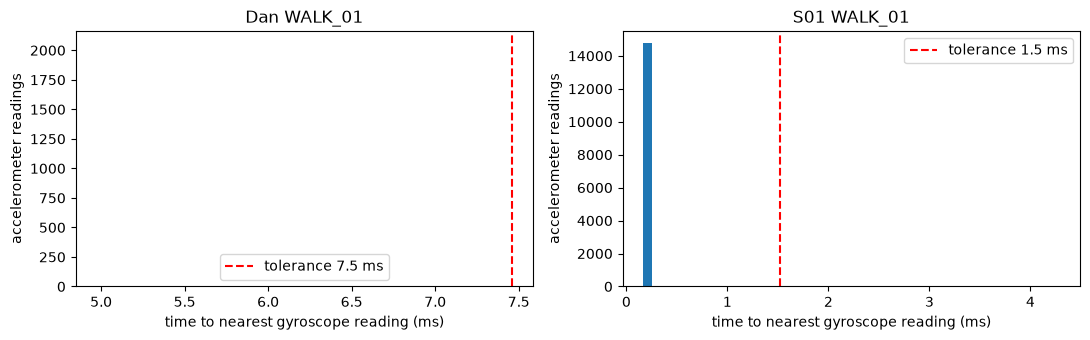

In [14]:
def nearest_gyro_gap(zip_path):
    a, _ = clean_sensor(read_sensor(zip_path, "Accelerometer"))
    g, _ = clean_sensor(read_sensor(zip_path, "Gyroscope"))
    tolerance_ms = 0.75 * max(a.t.diff().median(), g.t.diff().median()) * 1000

    g = g.rename(columns={"t": "gyro_t"})
    pairs = pd.merge_asof(a, g[["gyro_t"]], left_on="t", right_on="gyro_t", direction="nearest")
    gap_ms = (pairs.gyro_t - pairs.t).abs() * 1000

    return gap_ms, tolerance_ms


fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

for k in range(2):
    person, folder = people[k]
    gap_ms, tolerance_ms = nearest_gyro_gap(next(folder.rglob("WALK_01.zip")))

    ax = axes[k]
    ax.hist(gap_ms, bins=50)
    ax.axvline(tolerance_ms, color="red", ls="--", label=f"tolerance {tolerance_ms:.1f} ms")
    ax.set_xlabel("time to nearest gyroscope reading (ms)")
    ax.set_ylabel("accelerometer readings")
    ax.set_title(person + " WALK_01")
    ax.legend()

plt.tight_layout()
plt.show()

### 3.2 Hidden joins

If a recording was paused and started again, phyphox joins the pieces and the timestamps carry on with no gap. The only record of this is `meta/time.csv`.

Each START begins a run, and the run ends at the next PAUSE. Every run is kept, but windows are cut inside one run at a time, so no window crosses a join.

S03's `SIT_02.zip` is an example: 90 s made of three 30 s runs.

In [15]:
def find_runs(meta, duration):
    whole_file = [(0.0, duration)]

    if meta.empty or "event" not in meta.columns or "experiment time" not in meta.columns:
        return whole_file

    events = meta[["event", "experiment time"]].copy()
    events["event"] = events["event"].astype(str).str.upper()
    events["experiment time"] = pd.to_numeric(events["experiment time"], errors="coerce")
    events = events.dropna()

    starts = events[events.event == "START"]["experiment time"].tolist()
    pauses = events[events.event == "PAUSE"]["experiment time"].tolist()

    if len(starts) == 0 or len(pauses) == 0:
        return whole_file

    runs = []
    for start in starts:
        end = duration
        for pause in pauses:
            if pause > start + 1e-6 and pause < end:
                end = pause

        start = max(0.0, float(start))
        end = min(duration, float(end))
        if end > start:
            runs.append((start, end))

    if len(runs) == 0:
        return whole_file
    return runs

In [16]:
joined = POOL_DATA / "S03" / "SIT_02.zip"

joined_acc = read_sensor(joined, "Accelerometer")
joined_gyro = read_sensor(joined, "Gyroscope")
joined_meta = read_meta(joined, "time")

joined_aligned, _ = align_sensors(joined_acc, joined_gyro)
joined_runs = find_runs(joined_meta, joined_aligned.t.max())

display(joined_meta)
for start, end in joined_runs:
    print(f"run from {start:.2f} s to {end:.2f} s")

,event,experiment time,system time,system time text
0,START,0.000000,1.792233e+09,2026-10-17 12:37:55.268 UTC+02:00
1,PAUSE,30.049870,1.792234e+09,2026-10-17 12:38:25.318 UTC+02:00
2,START,30.049870,1.792234e+09,2026-10-17 12:38:43.204 UTC+02:00
3,PAUSE,60.106936,1.792234e+09,2026-10-17 12:39:13.261 UTC+02:00
4,START,60.106936,1.792234e+09,2026-10-17 12:39:30.241 UTC+02:00
5,PAUSE,90.152149,1.792234e+09,2026-10-17 12:40:00.286 UTC+02:00


run from 0.00 s to 30.05 s
run from 30.05 s to 60.11 s
run from 60.11 s to 90.15 s


### 3.3 Transitions

The first seconds of each run are the phone going into the pocket, and the last second can be the phone coming out. From the raw plots, this movement is over within about 5 s.

So I trim up to 5 s from the start of each run and 1 s from the end. If a run is too short for that, less is trimmed from the start so that at least one full window is left.

In [17]:
EDGE_TRIM_START = 5.0
EDGE_TRIM_END = 1.0


def trimmed_limits(run, length):
    first = float(run.t.min())
    last = float(run.t.max())

    time_to_spare = last - first - EDGE_TRIM_END - length
    start_trim = min(EDGE_TRIM_START, max(0.0, time_to_spare))

    return first + start_trim, last - EDGE_TRIM_END

Before and after: the top plot is the raw recording (red parts are trimmed, dashed lines are where a run starts), and the bottom plot is what is kept.

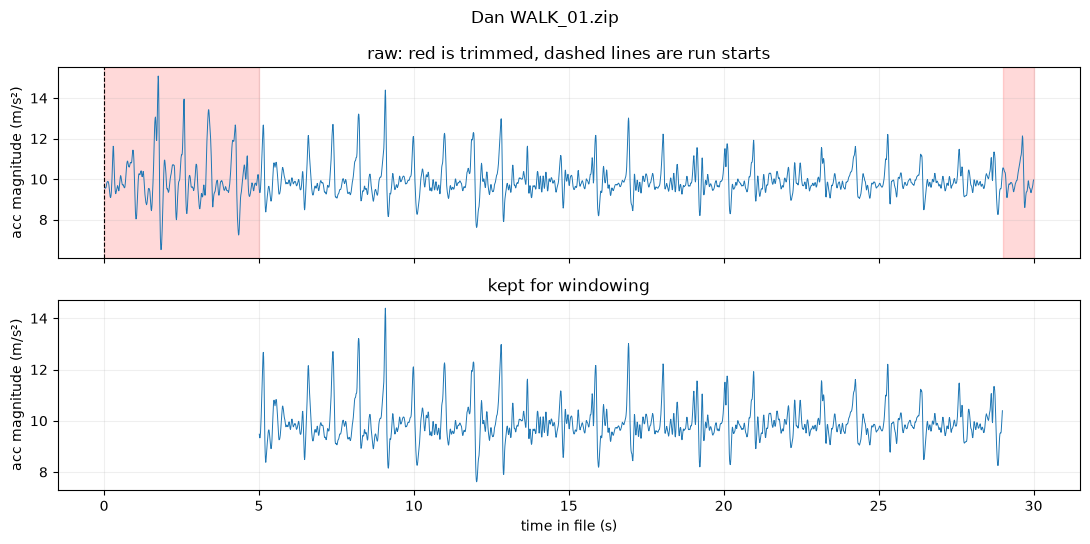

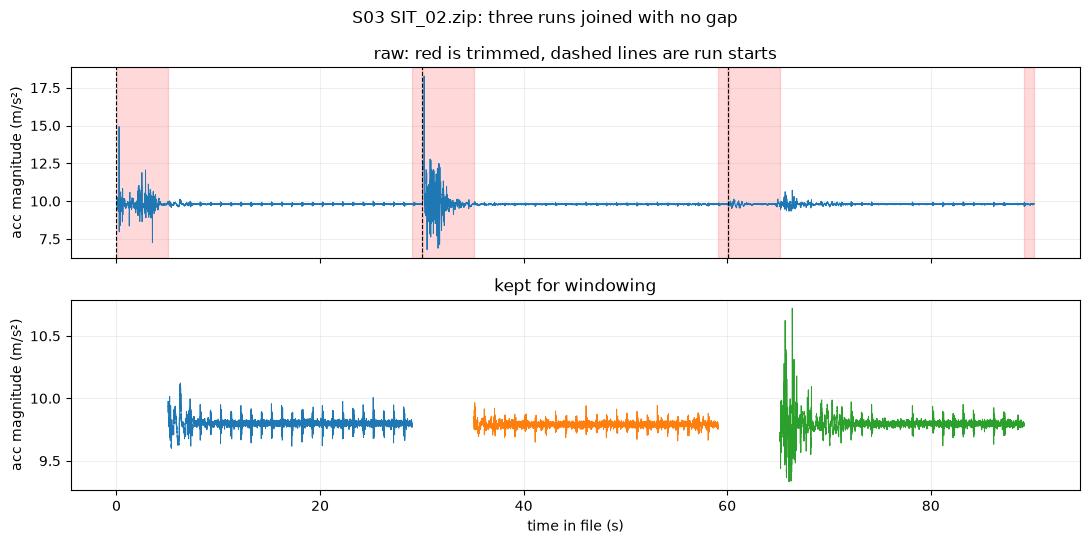

In [18]:
def plot_cleaning(aligned, runs, title, length=2.0):
    fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
    axes[0].plot(aligned.t, aligned.acc_mag, lw=0.7)

    for start, end in runs:
        run = aligned[(aligned.t >= start) & (aligned.t <= end)]
        keep_start, keep_end = trimmed_limits(run, length)

        axes[0].axvline(start, color="black", ls="--", lw=0.8)
        axes[0].axvspan(run.t.min(), keep_start, color="red", alpha=0.15)
        axes[0].axvspan(keep_end, run.t.max(), color="red", alpha=0.15)

        kept = run[(run.t >= keep_start) & (run.t <= keep_end)]
        axes[1].plot(kept.t, kept.acc_mag, lw=0.7)

    axes[0].set_title("raw: red is trimmed, dashed lines are run starts")
    axes[1].set_title("kept for windowing")
    axes[1].set_xlabel("time in file (s)")
    for ax in axes:
        ax.set_ylabel("acc magnitude (m/s²)")
        ax.grid(alpha=0.2)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_cleaning(aligned, find_runs(meta, aligned.t.max()), f"Dan {example.name}")
plot_cleaning(joined_aligned, joined_runs, "S03 SIT_02.zip: three runs joined with no gap")

### 3.4 Duplicate files

A recording counts as a duplicate if its readings are exactly the **start** of another recording by the same person. This catches:

- the same recording saved under two names (an exact copy),
- a file saved part-way through a paused recording, then saved again after more runs were added.

The shorter file is dropped, because everything in it is also in the longer one. For exact copies, the first file is kept.

In [19]:
def is_start_of(a, b):
    if len(a["acc"]) > len(b["acc"]) or len(a["gyro"]) > len(b["gyro"]):
        return False

    b_acc_start = b["acc"].iloc[:len(a["acc"])]
    b_gyro_start = b["gyro"].iloc[:len(a["gyro"])]

    return a["acc"].equals(b_acc_start) and a["gyro"].equals(b_gyro_start)


def find_copies(recordings):
    copies = {}

    for i in range(len(recordings)):
        a = recordings[i]

        for j in range(len(recordings)):
            b = recordings[j]
            if i == j or a["participant"] != b["participant"]:
                continue

            if is_start_of(a, b):
                a_is_shorter = len(a["acc"]) < len(b["acc"])
                if a_is_shorter or j < i:
                    copies[i] = b["recording"]
                    break

    return copies

## 4. From windows to a feature table

### 4.1 Windows

This is the starter's `make_windows`. The only change is that it can start and stop at given times, which are the trimmed limits from 3.3. It is run on one run at a time.

The window length and overlap are hyperparameters. One walking step takes about 0.5 s, so even 1 s windows hold a full step, and 2–3 s windows hold a few strides. Four settings are made here and the best one is chosen on validation data in Section 6. The first setting is also used for the label checks and the window counts.

To try a different window (for example at the viva), replace the list with just that setting, e.g. `[(1.5, 0.5)]`, and run all cells.

In [20]:
WINDOW_CONFIGS = [(2.0, 0.0), (1.0, 0.5), (2.0, 0.5), (3.0, 0.5)]   # (length in s, overlap)


def make_windows(df, length=2.0, overlap=0.5, start=None, last=None):
    step = length * (1 - overlap)

    if start is None:
        start = df.t.iloc[0]
    if last is None:
        last = df.t.iloc[-1]

    while start + length <= last:
        end = start + length
        rows = df[(df.t >= start) & (df.t < end)]
        yield start, end, rows
        start += step

In [21]:
first_run_end = find_runs(meta, aligned.t.max())[0][1]
run = aligned[(aligned.t >= 0) & (aligned.t <= first_run_end)]

keep_start, keep_end = trimmed_limits(run, 2.0)
windows = list(make_windows(run, 2.0, 0.5, keep_start, keep_end))
print(len(windows), "windows from", example.name)

start, end, rows = windows[10]
print(f"window 10 runs from {start:.2f} s to {end:.2f} s and holds {len(rows)} readings")

22 windows from WALK_01.zip
window 10 runs from 15.01 s to 17.01 s and holds 201 readings


Here is what one window looks like on its own.

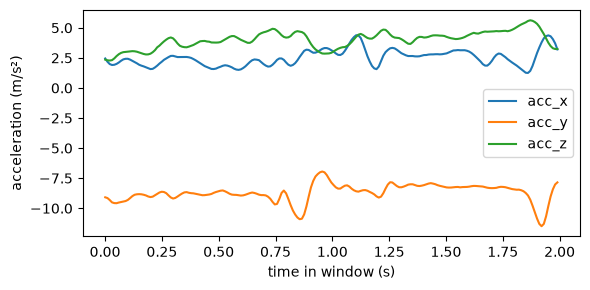

In [22]:
fig, ax = plt.subplots(figsize=(6, 3))
for col in ["acc_x", "acc_y", "acc_z"]:
    ax.plot(rows.t - start, rows[col], label=col)

ax.set_xlabel("time in window (s)")
ax.set_ylabel("acceleration (m/s²)")
ax.legend()
plt.tight_layout()
plt.show()

### 4.2 From a window to a row of numbers

The starter's five statistics (mean, standard deviation, minimum, maximum, range) for the three axes and the magnitude of both sensors. That is 8 signals × 5 = 40 features, named like `acc_y_mean` or `gyro_mag_sd`.

In [23]:
SIGNALS = ["acc_x", "acc_y", "acc_z", "acc_mag", "gyro_x", "gyro_y", "gyro_z", "gyro_mag"]


def window_stats(rows, columns):
    out = {}
    for col in columns:
        v = rows[col]
        out[f"{col}_mean"] = v.mean()
        out[f"{col}_sd"] = v.std()
        out[f"{col}_min"] = v.min()
        out[f"{col}_max"] = v.max()
        out[f"{col}_range"] = v.max() - v.min()
    return out


window_stats(rows, SIGNALS)

{'acc_x_mean': np.float64(2.51138203180597),
 'acc_x_sd': np.float64(0.6788783986399579),
 'acc_x_min': np.float64(1.250499573),
 'acc_x_max': np.float64(4.387675781),
 'acc_x_range': np.float64(3.1371762080000005),
 'acc_y_mean': np.float64(-8.707760774905472),
 'acc_y_sd': np.float64(0.746344368657516),
 'acc_y_min': np.float64(-11.49055527),
 'acc_y_max': np.float64(-6.944808197),
 'acc_y_range': np.float64(4.545747072999999),
 'acc_z_mean': np.float64(4.017038316850746),
 'acc_z_sd': np.float64(0.7046974467667141),
 'acc_z_min': np.float64(2.282154236),
 'acc_z_max': np.float64(5.627248077),
 'acc_z_range': np.float64(3.345093841),
 'acc_mag_mean': np.float64(9.960594346292474),
 'acc_mag_sd': np.float64(0.7517149002192093),
 'acc_mag_min': np.float64(8.18748499936872),
 'acc_mag_max': np.float64(13.014804321898854),
 'acc_mag_range': np.float64(4.827319322530133),
 'gyro_x_mean': np.float64(-0.035457357065527356),
 'gyro_x_sd': np.float64(0.2945820472078502),
 'gyro_x_min': np.flo

### 4.3 A feature table for one recording

Each row keeps the identifying columns (`participant`, `label`, `recording`, `nn`), because later the data is split by recording or by person, never by window. Windows with fewer than two readings are skipped.

In [24]:
def features_for_run(run, info, run_id, length=2.0, overlap=0.5):
    rows_out = []
    if run.empty:
        return rows_out

    keep_start, keep_end = trimmed_limits(run, length)

    for start, end, rows in make_windows(run, length, overlap, keep_start, keep_end):
        if len(rows) < 2:
            continue

        row = dict(info)
        row["run"] = run_id
        row["window"] = len(rows_out)
        row["window_seconds"] = length
        row["window_overlap"] = overlap
        row["start"] = start
        row["end"] = end
        row["samples"] = len(rows)
        row.update(window_stats(rows, SIGNALS))

        rows_out.append(row)

    return rows_out


def features_for_recording(aligned, runs, info, configs=WINDOW_CONFIGS):
    rows_out = []

    for run_id in range(len(runs)):
        start, end = runs[run_id]
        run = aligned[(aligned.t >= start) & (aligned.t <= end)]

        for length, overlap in configs:
            rows_out.extend(features_for_run(run, info, run_id, length, overlap))

    return rows_out

In [25]:
info = parse_name(example, OWN_DATA)
runs = find_runs(meta, aligned.t.max())

table = pd.DataFrame(features_for_recording(aligned, runs, info, [(2.0, 0.5)]))
table.head()

,participant,label,recording,nn,run,window,window_seconds,window_overlap,start,end,...,gyro_z_mean,gyro_z_sd,gyro_z_min,gyro_z_max,gyro_z_range,gyro_mag_mean,gyro_mag_sd,gyro_mag_min,gyro_mag_max,gyro_mag_range
0,Dan,WALK,WALK_01.zip,1,0,0,2.0,0.5,5.006447,7.006447,...,0.440485,0.311946,-0.051245,1.165377,1.216622,1.148156,0.569649,0.372416,2.390301,2.017884
1,Dan,WALK,WALK_01.zip,1,0,1,2.0,0.5,6.006447,8.006447,...,0.276851,0.307721,-0.512928,0.767479,1.280406,0.991408,0.492097,0.206110,2.235703,2.029593
2,Dan,WALK,WALK_01.zip,1,0,2,2.0,0.5,7.006447,9.006447,...,0.181964,0.298935,-0.512928,0.690354,1.203282,0.831188,0.272334,0.206110,1.629063,1.422954
3,Dan,WALK,WALK_01.zip,1,0,3,2.0,0.5,8.006447,10.006447,...,-0.091208,0.450182,-0.836735,0.788375,1.625109,0.939395,0.379682,0.265198,1.884150,1.618952
4,Dan,WALK,WALK_01.zip,1,0,4,2.0,0.5,9.006447,11.006447,...,-0.451270,0.466297,-1.195983,0.788375,1.984357,1.221104,0.549444,0.265198,2.393682,2.128484


## 5. All recordings

Read every zip file, mine first and then the pool. Files with a wrong name or that cannot be read are written to the quality log and skipped.

In [26]:
recordings = []
quality_rows = []

for dataset, root in [("Dan", OWN_DATA), ("Pool", POOL_DATA)]:
    for f in find_zips(root):
        info = parse_name(f, root)

        if info is None:
            quality_rows.append({"dataset": dataset, "recording": f.name,
                                 "status": "excluded_bad_name", "reason": "name does not match the pattern"})
            continue

        try:
            rec = dict(info)
            rec["dataset"] = dataset
            rec["acc"] = read_sensor(f, "Accelerometer")
            rec["gyro"] = read_sensor(f, "Gyroscope")
            rec["meta"] = read_meta(f, "time")
            recordings.append(rec)
        except (ValueError, FileNotFoundError, zipfile.BadZipFile, pd.errors.ParserError) as error:
            quality_rows.append({"dataset": dataset, "participant": info["participant"], "recording": f.name,
                                 "status": "excluded_unreadable", "reason": str(error)})

print(len(recordings), "recordings read,", len(quality_rows), "skipped")

200 recordings read, 0 skipped


**Which pooled person is me?** My files are in the pool under an anonymous code. If a pooled recording has exactly the same accelerometer and gyroscope readings as my recording with the same name, it must be mine.

In [27]:
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

own = {}
for rec in recordings:
    if rec["participant"] == "Dan":
        own[rec["recording"]] = rec

identity_rows = []
for rec in recordings:
    if rec["participant"] == "Dan" or rec["recording"] not in own:
        continue

    mine = own[rec["recording"]]
    if rec["acc"].equals(mine["acc"]) and rec["gyro"].equals(mine["gyro"]):
        identity_rows.append({"participant": rec["participant"], "recording": rec["recording"]})

identity = pd.DataFrame(identity_rows)
identity.to_csv(RESULTS / "self_identity_matches.csv", index=False)

match_counts = identity.participant.value_counts()
self_person = match_counts.index[0]
print(match_counts.iloc[0], "of my recordings are identical to", self_person + "'s, so", self_person, "is me.")

40 of my recordings are identical to S04's, so S04 is me.


**Duplicates.** Apply the rule from 3.4 within each person.

In [28]:
copies = find_copies(recordings)

for i in copies:
    rec = recordings[i]
    print(f"{rec['participant']}/{rec['recording']} repeats the start of {copies[i]}")

S03/SIT_01.zip repeats the start of SIT_02.zip
S03/SIT_03.zip repeats the start of SIT_04.zip
S03/SIT_04.zip repeats the start of SIT_05.zip


The evidence: S03's `SIT_01.zip` lies exactly on the first 60 s of `SIT_02.zip`.

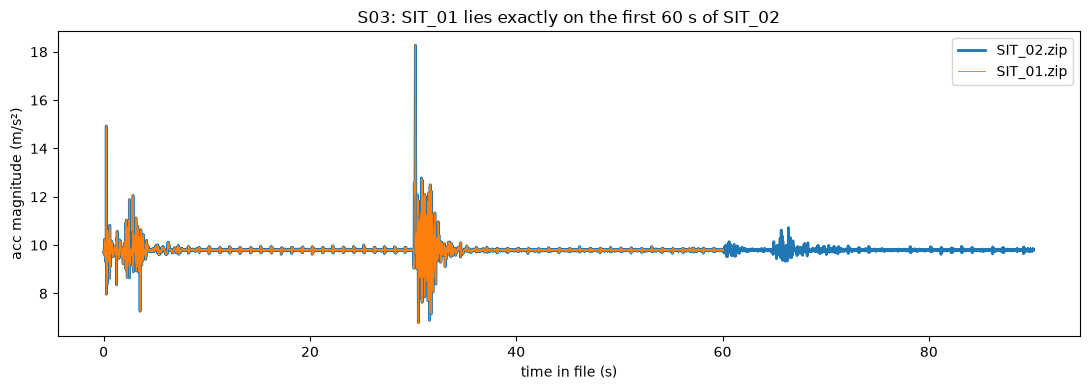

In [29]:
s03 = {}
for rec in recordings:
    if rec["participant"] == "S03":
        s03[rec["recording"]] = rec

fig, ax = plt.subplots(figsize=(11, 4))
for name, width in [("SIT_02.zip", 2.0), ("SIT_01.zip", 0.7)]:
    a = s03[name]["acc"]
    ax.plot(a.t, np.sqrt(a.x**2 + a.y**2 + a.z**2), lw=width, label=name)

ax.set_xlabel("time in file (s)")
ax.set_ylabel("acc magnitude (m/s²)")
ax.set_title("S03: SIT_01 lies exactly on the first 60 s of SIT_02")
ax.legend()
plt.tight_layout()
plt.show()

**Clean and window every recording.** Duplicates are skipped. Every other recording is aligned, split into runs, trimmed and cut into windows for every window setting. A quality row records what cleaning did to each file.

In [30]:
feature_rows = []

for i in range(len(recordings)):
    rec = recordings[i]
    base = {"dataset": rec["dataset"], "participant": rec["participant"],
            "recording": rec["recording"], "label": rec["label"]}

    if i in copies:
        row = dict(base)
        row["status"] = "excluded_duplicate"
        row["reason"] = "sensor readings repeat the start of " + copies[i]
        quality_rows.append(row)
        continue

    aligned, align_info = align_sensors(rec["acc"], rec["gyro"])

    if aligned.empty:
        row = dict(base)
        row["status"] = "excluded_unusable"
        row["reason"] = "too few valid aligned sensor readings"
        quality_rows.append(row)
        continue

    runs = find_runs(rec["meta"], float(aligned.t.max()))

    row = dict(base)
    row["acc_rows"] = len(rec["acc"])
    row["gyro_rows"] = len(rec["gyro"])
    row["acc_x_mean"] = rec["acc"].x.mean()
    row["acc_y_mean"] = rec["acc"].y.mean()
    row["acc_z_mean"] = rec["acc"].z.mean()
    row["aligned_rows"] = len(aligned)
    row.update(align_info)
    row["duration_s"] = float(aligned.t.max())
    row["runs"] = len(runs)
    row["status"] = "included"
    row["reason"] = ""
    quality_rows.append(row)

    info = {"participant": rec["participant"], "label": rec["label"],
            "recording": rec["recording"], "nn": rec["nn"]}
    feature_rows.extend(features_for_recording(aligned, runs, info))

Save the quality log and the feature table. The table is read back from the CSV so the rest of the notebook uses exactly what is saved.

In [31]:
quality = pd.DataFrame(quality_rows)
quality.to_csv(RESULTS / "data_quality_log.csv", index=False)

pd.DataFrame(feature_rows).to_csv(RESULTS / "window_features.csv", index=False)
features = pd.read_csv(RESULTS / "window_features.csv")
print(features.shape, "feature table")

problems = quality[(quality.status != "included") | (quality.runs > 1)]
problems[["participant", "recording", "status", "runs", "reason"]]

(19083, 51) feature table


,participant,recording,status,runs,reason
125,S03,SIT_01.zip,excluded_duplicate,NaN,sensor readings repeat the start of SIT_02.zip
126,S03,SIT_02.zip,included,3.0,
127,S03,SIT_03.zip,excluded_duplicate,NaN,sensor readings repeat the start of SIT_04.zip
128,S03,SIT_04.zip,excluded_duplicate,NaN,sensor readings repeat the start of SIT_05.zip
129,S03,SIT_05.zip,included,3.0,
149,S03,UP_05.zip,included,3.0,


How many accelerometer readings each person lost because they had no gyroscope reading close enough in time.

In [32]:
quality.groupby("participant")[["aligned_rows", "unmatched_acc_rows"]].sum()

,aligned_rows,unmatched_acc_rows
participant,,
Dan,120668.0,9.0
S01,593174.0,54.0
S02,480430.0,0.0
S03,620066.0,132.0
S04,120668.0,9.0


**Class imbalance.** Recordings per person and activity after cleaning. The protocol asks for 5 recordings of each stair class and 10 of the others, so the stair classes have about half as many windows. S03 has 7 sitting recordings because three duplicates were removed, although the joined files still hold all their runs.

This is handled in two ways: the models can use class weights (Section 6), and models are compared with macro F1, where every class counts equally.

In [33]:
included = quality[quality.status == "included"]
pd.crosstab(included.participant, included.label)[LABELS]

label,SIT,STAND,WALK,UP,DOWN
participant,,,,,
Dan,10,10,10,5,5
S01,10,10,10,5,5
S02,10,10,10,5,5
S03,7,10,10,5,5
S04,10,10,10,5,5


**Label check.** A recording whose movement is far from the rest of its class might have the wrong label. For each person and activity, a recording is flagged if:

- its average `acc_mag_sd` or `gyro_mag_sd` is more than 3 times, or less than a third of, the class median, or
- its `acc_mag_sd` is much closer to another activity's median than to its own.

A flag only means "look at the raw plot". Labels are not changed automatically.

In [34]:
check_columns = ["acc_mag_sd", "gyro_mag_sd"]

length, overlap = WINDOW_CONFIGS[0]
selected = features[(features.window_seconds == length) & (features.window_overlap == overlap)]
summary = selected.groupby(["participant", "label", "recording"])[check_columns].mean().reset_index()
summary.to_csv(RESULTS / "label_sanity_summary.csv", index=False)

review_rows = []

for person, person_data in summary.groupby("participant"):

    for label, label_data in person_data.groupby("label"):
        for col in check_columns:
            middle = label_data[col].median()

            for _, row in label_data.iterrows():
                if row[col] < middle / 3 or row[col] > middle * 3:
                    review_rows.append({"participant": person, "label": label, "recording": row.recording,
                                        "signal": col, "value": row[col], "class_median": middle})

    centres = person_data.groupby("label")["acc_mag_sd"].median()

    for _, row in person_data.iterrows():
        distance = (centres - row.acc_mag_sd).abs()
        closest = distance.idxmin()

        if closest != row.label and distance[closest] < distance[row.label] / 2:
            review_rows.append({"participant": person, "label": row.label, "recording": row.recording,
                                "signal": "movement_closer_to", "value": closest,
                                "class_median": centres[row.label]})

print(len(review_rows), "movement flags")

24 movement flags


**Tilt check.** When the phone is still, the accelerometer only measures gravity, so the mean of x, y and z shows how the phone is tilted. Sitting puts the thigh flat and standing puts it upright, so a sitting recording should have a tilt close to the person's other sitting recordings.

Walking and stairs also keep the thigh upright, so tilt cannot separate them from standing. This check is only for SIT and STAND.

For each person, I take the median tilt of their SIT recordings and of their STAND recordings. A recording is flagged if its tilt is closer to the other class than to its own, or more than 60° away from its own class.

In [35]:
TILT = ["acc_x_mean", "acc_y_mean", "acc_z_mean"]


def angle_between(u, v):
    cos = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
    return np.degrees(np.arccos(np.clip(cos, -1, 1)))

In [36]:
tilt = selected.groupby(["participant", "label", "recording"])[TILT].mean().reset_index()
still = tilt[tilt.label.isin(["SIT", "STAND"])].copy()

for person, person_data in still.groupby("participant"):
    sit_centre = person_data[person_data.label == "SIT"][TILT].median().to_numpy()
    stand_centre = person_data[person_data.label == "STAND"][TILT].median().to_numpy()

    for i, row in person_data.iterrows():
        gravity = row[TILT].to_numpy(dtype=float)
        still.loc[i, "angle_to_SIT"] = angle_between(gravity, sit_centre)
        still.loc[i, "angle_to_STAND"] = angle_between(gravity, stand_centre)

tilt_flags = []
for _, row in still.iterrows():
    if row.label == "SIT":
        own, other = row.angle_to_SIT, row.angle_to_STAND
    else:
        own, other = row.angle_to_STAND, row.angle_to_SIT

    if other < own or own > 60:
        tilt_flags.append(row)
        review_rows.append({"participant": row.participant, "label": row.label, "recording": row.recording,
                            "signal": "tilt", "value": f"{own:.0f} deg from own class, {other:.0f} deg from other",
                            "class_median": np.nan})

review_table = pd.DataFrame(review_rows)
review_table.to_csv(RESULTS / "label_review_candidates.csv", index=False)
print(len(review_table), "flags for label review in total")

pd.DataFrame(tilt_flags)[["participant", "label", "recording", "angle_to_SIT", "angle_to_STAND"]].round(1)

30 flags for label review in total


,participant,label,recording,angle_to_SIT,angle_to_STAND
11,Dan,SIT,SIT_07.zip,17.6,14.4
45,S01,SIT,SIT_01.zip,149.4,121.3
63,S01,STAND,STAND_09.zip,127.9,62.3
87,S02,SIT,SIT_03.zip,51.4,21.2
94,S02,SIT,SIT_10.zip,135.8,76.1
168,S04,SIT,SIT_07.zip,17.6,14.4


Each dot is one recording. Sitting recordings should sit above the dashed line (close to SIT, far from STAND) and standing recordings below it. Flagged recordings are named.

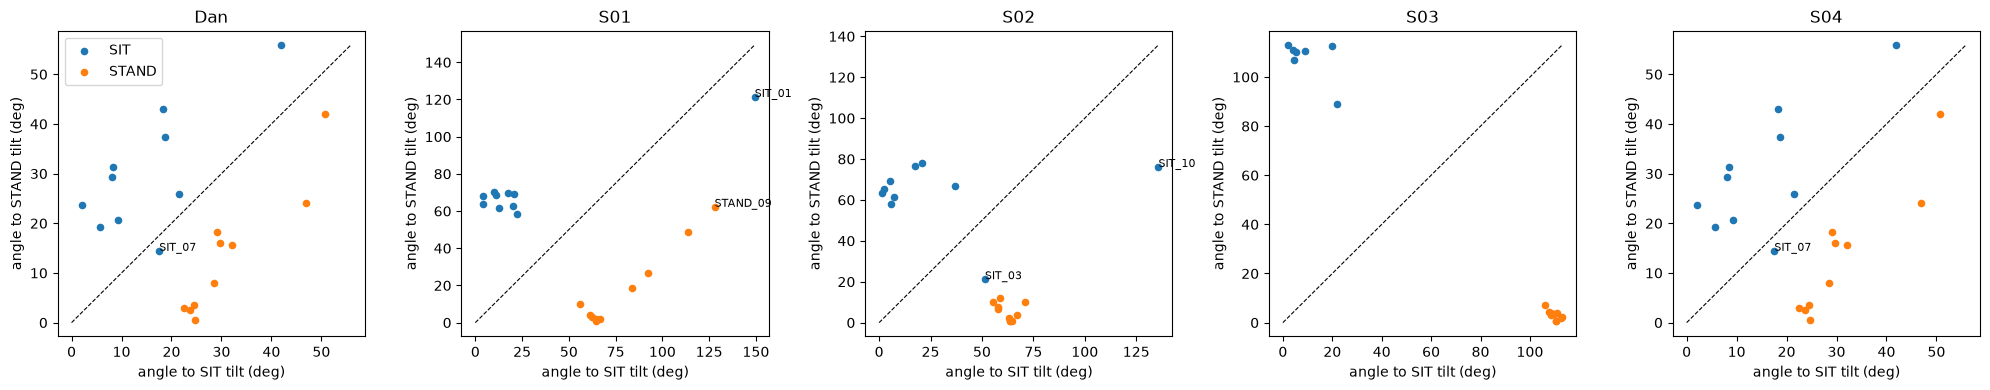

In [37]:
people_codes = sorted(still.participant.unique())
fig, axes = plt.subplots(1, len(people_codes), figsize=(4 * len(people_codes), 4))

for k in range(len(people_codes)):
    person = people_codes[k]
    ax = axes[k]
    data = still[still.participant == person]

    for label, grp in data.groupby("label"):
        ax.scatter(grp.angle_to_SIT, grp.angle_to_STAND, s=20, label=label)

    for row in tilt_flags:
        if row.participant == person:
            ax.annotate(row.recording.replace(".zip", ""), (row.angle_to_SIT, row.angle_to_STAND), fontsize=8)

    biggest = max(data.angle_to_SIT.max(), data.angle_to_STAND.max())
    ax.plot([0, biggest], [0, biggest], color="black", ls="--", lw=0.8)
    ax.set_xlabel("angle to SIT tilt (deg)")
    ax.set_ylabel("angle to STAND tilt (deg)")
    ax.set_title(person)

axes[0].legend()
plt.tight_layout()
plt.show()

**All flags together.** A flag only means "look at this recording". A tilt far from both classes (like S01's SIT_01, over 120° from both) most likely means the phone sat a different way in the pocket. That changes the axes but not the activity, and the magnitude features are not affected. Labels are kept as they are, and any flagged file can be checked with the raw plot below.

,participant,label,recording,signal,value,class_median
0,Dan,SIT,SIT_03.zip,gyro_mag_sd,0.034418,0.003132
1,Dan,STAND,STAND_10.zip,gyro_mag_sd,0.04699,0.012203
2,Dan,DOWN,DOWN_01.zip,movement_closer_to,UP,3.333027
3,S01,SIT,SIT_01.zip,gyro_mag_sd,0.013976,0.003782
4,S01,STAND,STAND_02.zip,gyro_mag_sd,0.002622,0.008449
5,S01,STAND,STAND_04.zip,gyro_mag_sd,0.00255,0.008449
6,S01,SIT,SIT_06.zip,movement_closer_to,STAND,0.016854
7,S01,SIT,SIT_08.zip,movement_closer_to,STAND,0.016854
8,S01,SIT,SIT_10.zip,movement_closer_to,STAND,0.016854
9,S01,STAND,STAND_01.zip,movement_closer_to,SIT,0.015536


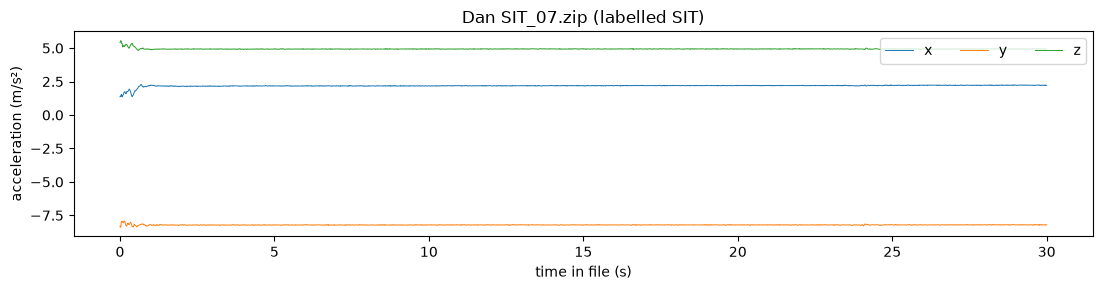

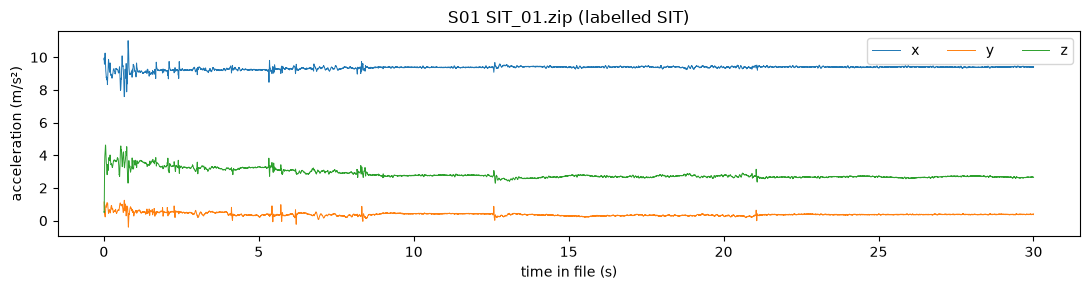

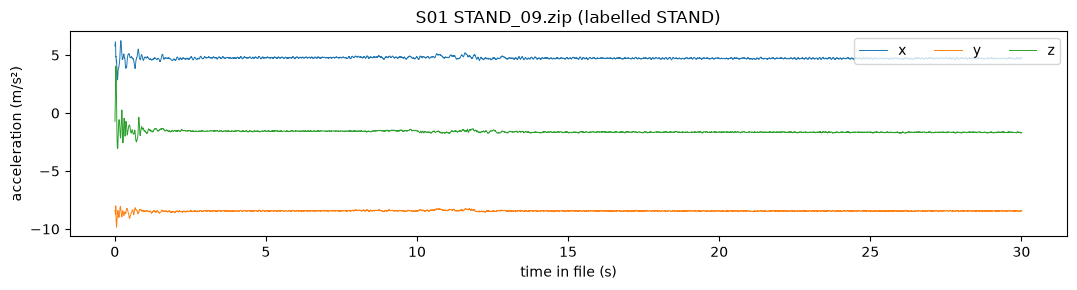

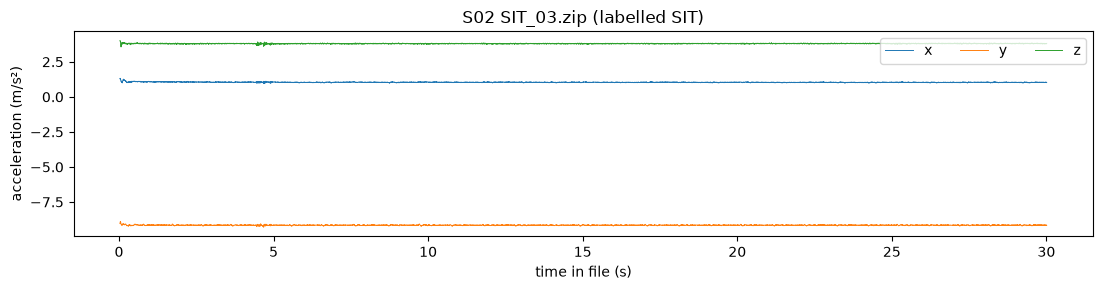

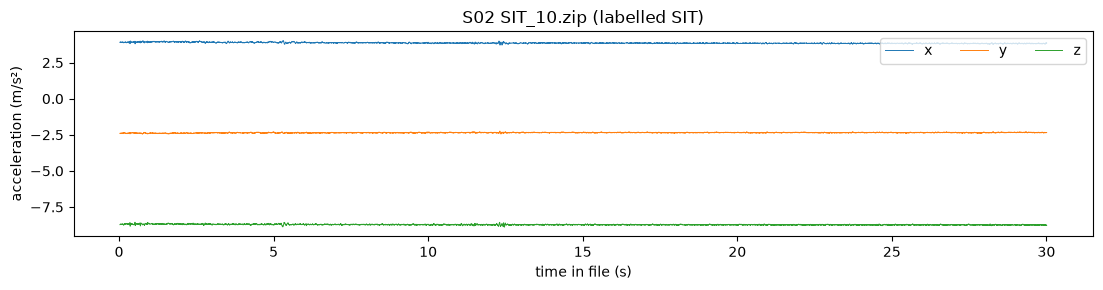

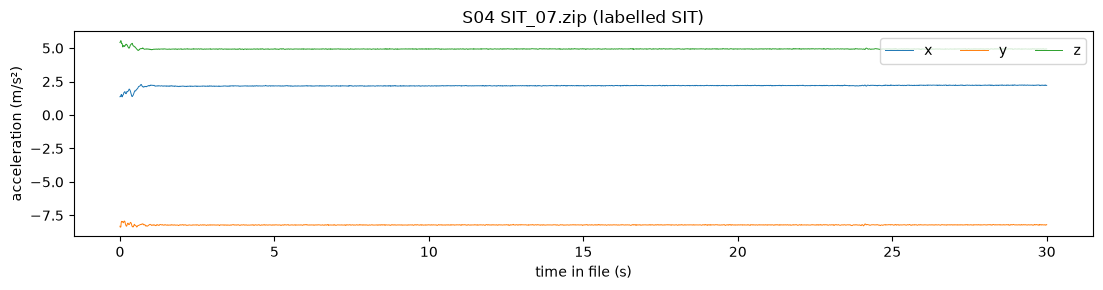

In [38]:
def plot_recording(person, recording):
    for rec in recordings:
        if rec["participant"] == person and rec["recording"] == recording:
            a = rec["acc"]
            fig, ax = plt.subplots(figsize=(11, 3))
            for axis in ["x", "y", "z"]:
                ax.plot(a.t, a[axis], lw=0.7, label=axis)
            ax.set_xlabel("time in file (s)")
            ax.set_ylabel("acceleration (m/s²)")
            ax.set_title(f"{person} {recording} (labelled {rec['label']})")
            ax.legend(loc="upper right", ncol=3)
            plt.tight_layout()
            plt.show()


display(review_table)

for row in tilt_flags:
    plot_recording(row.participant, row.recording)

A first look at whether two features separate my activities, like in the starter. Movement (`acc_mag_sd`) separates still from moving, and tilt (`acc_y_mean`) separates sitting from standing.

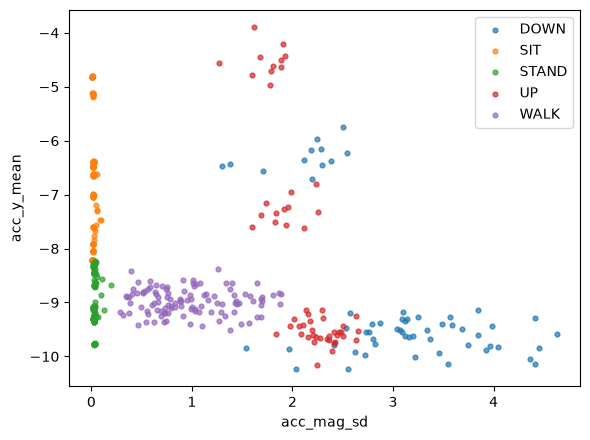

In [39]:
mine = selected[selected.participant == "Dan"]

fig, ax = plt.subplots(figsize=(6, 4.5))
for label, grp in mine.groupby("label"):
    ax.scatter(grp["acc_mag_sd"], grp["acc_y_mean"], s=12, label=label, alpha=0.7)

ax.set_xlabel("acc_mag_sd")
ax.set_ylabel("acc_y_mean")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Splitting my data and choosing settings

Neighbouring windows are almost the same, and overlapping windows share readings. So all windows from one recording must go into the same split, otherwise the test score is too high.

| | SIT, STAND, WALK | UP, DOWN |
|---|---|---|
| train | 01–05 | 01–03 |
| validation | 06–07 | 04 |
| test | 08–10 | 05 |

The window setting, the feature group and the hyperparameters are all chosen on the validation recordings. The test recordings are only used at the end.

In [40]:
def within_person_split(df):
    stairs = df.label.isin(["UP", "DOWN"])

    train = df[(stairs & (df.nn <= 3)) | (~stairs & (df.nn <= 5))]
    validation = df[(stairs & (df.nn == 4)) | (~stairs & (df.nn >= 6) & (df.nn <= 7))]
    test = df[(stairs & (df.nn >= 5)) | (~stairs & (df.nn >= 8))]

    return train.copy(), validation.copy(), test.copy()


def pick(df, length, overlap):
    return df[(df.window_seconds == length) & (df.window_overlap == overlap)]

In [41]:
train, validation, test = within_person_split(features[features.participant == "Dan"])

assert len(set(train.recording) & set(validation.recording)) == 0
assert len(set(train.recording) & set(test.recording)) == 0
assert len(set(validation.recording) & set(test.recording)) == 0

split_rows = []
for split_name, split_data in [("train", train), ("validation", validation), ("test", test)]:
    for recording in sorted(split_data.recording.unique()):
        split_rows.append({"split": split_name, "recording": recording})
    print(split_name, split_data.recording.nunique(), "recordings")

pd.DataFrame(split_rows).to_csv(RESULTS / "recording_splits.csv", index=False)

train 21 recordings
validation 8 recordings
test 11 recordings


Windows per activity in each split (using the first window setting), showing the class imbalance the models train on.

In [42]:
window_counts = pd.DataFrame({
    "train": pick(train, length, overlap).label.value_counts(),
    "validation": pick(validation, length, overlap).label.value_counts(),
    "test": pick(test, length, overlap).label.value_counts(),
})
window_counts.loc[LABELS]

,train,validation,test
label,,,
SIT,56,22,34
STAND,56,22,33
WALK,56,22,33
UP,34,11,11
DOWN,36,12,11


**Feature groups.** To see whether the axes or the magnitudes are more useful, every setting is tried with three groups: all 40 features, the axes only (these carry the phone's tilt), and the magnitudes only (these do not depend on how the phone sits in the pocket).

In [43]:
FEATURES = []
for col in features.columns:
    if col.startswith("acc_") or col.startswith("gyro_"):
        FEATURES.append(col)

axes_only = []
magnitudes_only = []
for col in FEATURES:
    if "_mag_" in col:
        magnitudes_only.append(col)
    else:
        axes_only.append(col)

FEATURE_GROUPS = {
    "axes_and_magnitudes": FEATURES,
    "axes_only": axes_only,
    "magnitudes_only": magnitudes_only,
}

for name in FEATURE_GROUPS:
    print(name, len(FEATURE_GROUPS[name]), "features")

axes_and_magnitudes 40 features
axes_only 30 features
magnitudes_only 10 features


**The two classifiers** are from different families:

- **Logistic regression** (linear model) draws flat boundaries using a weighted sum of the features. It is trained by minimising **log loss**. The features are standardised first. The scaler is inside the pipeline, so it only learns from the training data.
- **Random forest** (tree ensemble) asks yes/no questions about single features. Each split is chosen to reduce **Gini impurity**, and 160 trees vote. It does not need scaling.

`class_weight="balanced"` makes the stair classes, which have fewer recordings, count as much as the others.

Every combination is scored by **macro F1** on the validation recordings, and the best one is kept.

In [44]:
import json

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def make_model(name, params):
    if name == "LogisticRegression":
        classifier = LogisticRegression(max_iter=3000, random_state=42,
                                        C=params["C"], class_weight=params["class_weight"])
        return Pipeline([("scale", StandardScaler()), ("classifier", classifier)])

    return RandomForestClassifier(n_estimators=160, max_features="sqrt", random_state=42, n_jobs=-1,
                                  max_depth=params["max_depth"],
                                  min_samples_leaf=params["min_samples_leaf"],
                                  class_weight=params["class_weight"])


CANDIDATES = {"LogisticRegression": [], "RandomForest": []}

for c in [0.1, 1.0, 10.0]:
    for weight in [None, "balanced"]:
        CANDIDATES["LogisticRegression"].append({"C": c, "class_weight": weight})

for depth in [None, 16]:
    for leaf in [1, 3]:
        CANDIDATES["RandomForest"].append({"max_depth": depth, "min_samples_leaf": leaf,
                                           "class_weight": "balanced_subsample"})

In [45]:
def find_best_config(name, train, validation):
    configs = train[["window_seconds", "window_overlap"]].drop_duplicates()
    configs = configs.sort_values(["window_seconds", "window_overlap"])

    tried = []
    best = None

    for _, config in configs.iterrows():
        length = config["window_seconds"]
        overlap = config["window_overlap"]
        train_part = pick(train, length, overlap)
        val_part = pick(validation, length, overlap)

        for set_name, cols in FEATURE_GROUPS.items():
            for params in CANDIDATES[name]:
                model = make_model(name, params)
                model.fit(train_part[cols], train_part.label.to_numpy())
                predictions = model.predict(val_part[cols])
                score = f1_score(val_part.label.to_numpy(), predictions,
                                 labels=LABELS, average="macro", zero_division=0)

                result = {"model": name, "window_seconds": length, "window_overlap": overlap,
                          "feature_set": set_name, "parameters": json.dumps(params, sort_keys=True),
                          "validation_macro_f1": score, "selected": False}
                tried.append(result)

                if best is None or score > best["validation_macro_f1"]:
                    best = result
                    best_params = params

    best["selected"] = True
    best = dict(best)
    best["params"] = best_params
    return best, tried

## 7. Testing the models

### 7.1 The clinic's costs

Stair use matters most to the clinic. Each window costs (rows are the true activity, columns are the prediction):

In [46]:
COST = np.array([[0, 1, 1, 3, 3],      # brief, Section 5
                 [1, 0, 1, 3, 3],
                 [1, 1, 0, 3, 3],
                 [10, 10, 10, 0, 2],
                 [10, 10, 10, 2, 0]])

pd.DataFrame(COST, index=LABELS, columns=LABELS)

,SIT,STAND,WALK,UP,DOWN
SIT,0,1,1,3,3
STAND,1,0,1,3,3
WALK,1,1,0,3,3
UP,10,10,10,0,2
DOWN,10,10,10,2,0


Two decision rules are compared for the same trained model:

- **argmax**: predict the most likely activity,
- **minimum expected cost**: for each window, use the predicted probabilities to work out the expected cost of each possible prediction, and pick the cheapest one. This can predict a stair class even when walking is more likely, because missing a stair bout costs much more.

In [47]:
POLICIES = ["argmax", "minimum_expected_cost"]


def predict(model, df, columns, policy="argmax"):
    probabilities = model.predict_proba(df[columns])

    if policy == "argmax":
        return model.classes_[probabilities.argmax(axis=1)]

    cost_rows = []
    for c in model.classes_:
        cost_rows.append(COST[LABELS.index(c)])
    cost_rows = np.array(cost_rows)

    predictions = []
    for p in probabilities:
        expected_costs = p @ cost_rows   # expected cost of each possible prediction
        predictions.append(LABELS[expected_costs.argmin()])

    return np.array(predictions)


def expected_cost(y_true, y_pred):
    if len(y_true) == 0:
        return np.nan

    total = 0
    for true_label, predicted_label in zip(y_true, y_pred):
        total += COST[LABELS.index(true_label), LABELS.index(predicted_label)]

    return float(total / len(y_true) * 1000)

### 7.2 Measures

Accuracy alone hides how the stair classes do, because they have fewer windows. So every test reports accuracy, balanced accuracy, **macro F1** (every class counts equally), precision and recall for each class, and the expected cost per 1,000 windows.

In [48]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support


def compute_metrics(y_true, y_pred):
    precision, recall, _, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS,
                                                              average=None, zero_division=0)
    metrics = {
        "windows": len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "expected_cost_per_1000": expected_cost(y_true, y_pred),
    }

    for i in range(len(LABELS)):
        metrics["precision_" + LABELS[i]] = precision[i]
    for i in range(len(LABELS)):
        metrics["recall_" + LABELS[i]] = recall[i]

    return metrics


def plot_confusion(ax, y_true, y_pred, title, experiment, confusion_rows):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)

    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(LABELS)), LABELS, rotation=35, ha="right")
    ax.set_yticks(range(len(LABELS)), LABELS)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.set_title(title)

    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            colour = "white" if cm[i, j] > cm.max() / 2 else "black"
            ax.text(j, i, cm[i, j], ha="center", va="center", color=colour)

            confusion_rows.append({"experiment": experiment, "true_label": LABELS[i],
                                   "predicted_label": LABELS[j], "count": int(cm[i, j])})

### 7.3 Experiment 1 (within-person) and Experiment 2 (across people)

For each classifier:

1. choose the settings on validation data,
2. train again on train + validation with those settings,
3. test once on my held-out test recordings (Experiment 1),
4. without changing anything, test on each pooled person (Experiment 2).

S01–S03 are other people, so all their usable recordings are used. For my own copy in the pool, only my test recordings are used, because the others were used for training.

A model is trained for each feature group so the groups can also be compared across people, but the reported model is the group chosen on validation.

In [49]:
def evaluate_within(name, model, columns, test_data, best, confusion_rows):
    rows = []
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    if name == "LogisticRegression":
        model_label = "Logistic regression"
    else:
        model_label = "Random forest"

    for k in range(len(POLICIES)):
        policy = POLICIES[k]
        predictions = predict(model, test_data, columns, policy)

        row = {"experiment": "within_person_test", "model": name, "policy": policy,
               "feature_set": best["feature_set"], "window_seconds": best["window_seconds"],
               "window_overlap": best["window_overlap"], "parameters": best["parameters"]}
        row.update(compute_metrics(test_data.label.to_numpy(), predictions))
        rows.append(row)

        experiment = f"Personal test: {model_label} ({policy.replace('_', ' ')})"
        plot_confusion(axes[k], test_data.label, predictions, policy, experiment, confusion_rows)

    fig.suptitle(f"Experiment 1, my test recordings: {name}")
    plt.tight_layout()
    plt.show()
    return rows

In [50]:
def my_test_recordings(data):
    stairs = data.label.isin(["UP", "DOWN"])
    return data[(~stairs & (data.nn >= 8)) | (stairs & (data.nn >= 5))]


def evaluate_across(name, models, pool, best, self_person, confusion_rows):
    rows = []
    people = sorted(pool.participant.unique())
    fig, axes = plt.subplots(2, len(people), figsize=(4.5 * len(people), 9), squeeze=False)

    for col in range(len(people)):
        person = people[col]
        data = pool[pool.participant == person]
        scope = "unseen_participant_all_usable_recordings"
        title_name = person

        if person == self_person:
            data = my_test_recordings(data)
            scope = "self_identity_reference_held_out_recordings"
            title_name = person + " (me)"

        for set_name, model in models.items():
            for k in range(len(POLICIES)):
                policy = POLICIES[k]
                predictions = predict(model, data, FEATURE_GROUPS[set_name], policy)

                row = {"model": name, "person": person, "feature_set": set_name, "scope": scope,
                       "policy": policy, "window_seconds": best["window_seconds"],
                       "window_overlap": best["window_overlap"]}
                row.update(compute_metrics(data.label.to_numpy(), predictions))
                rows.append(row)

                if set_name == best["feature_set"]:
                    experiment = f"Across-person | {person} | {name} | {policy}"
                    plot_confusion(axes[k, col], data.label, predictions, f"{title_name}, {policy}",
                                   experiment, confusion_rows)

    fig.suptitle(f"Experiment 2, each pooled person: {name} ({best['feature_set']})")
    plt.tight_layout()
    plt.show()
    return rows

Run both experiments for both classifiers.

LogisticRegression: 2.0 s windows, 0% overlap, axes_and_magnitudes, {'C': 1.0, 'class_weight': None}
validation macro F1 1.000


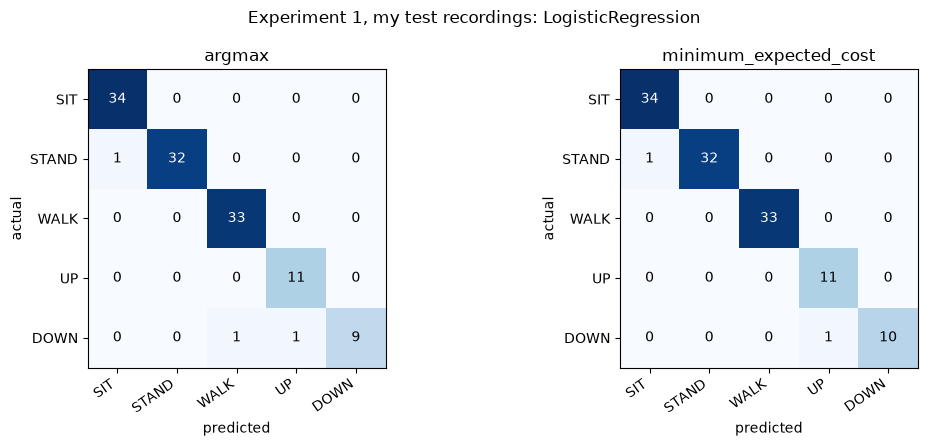

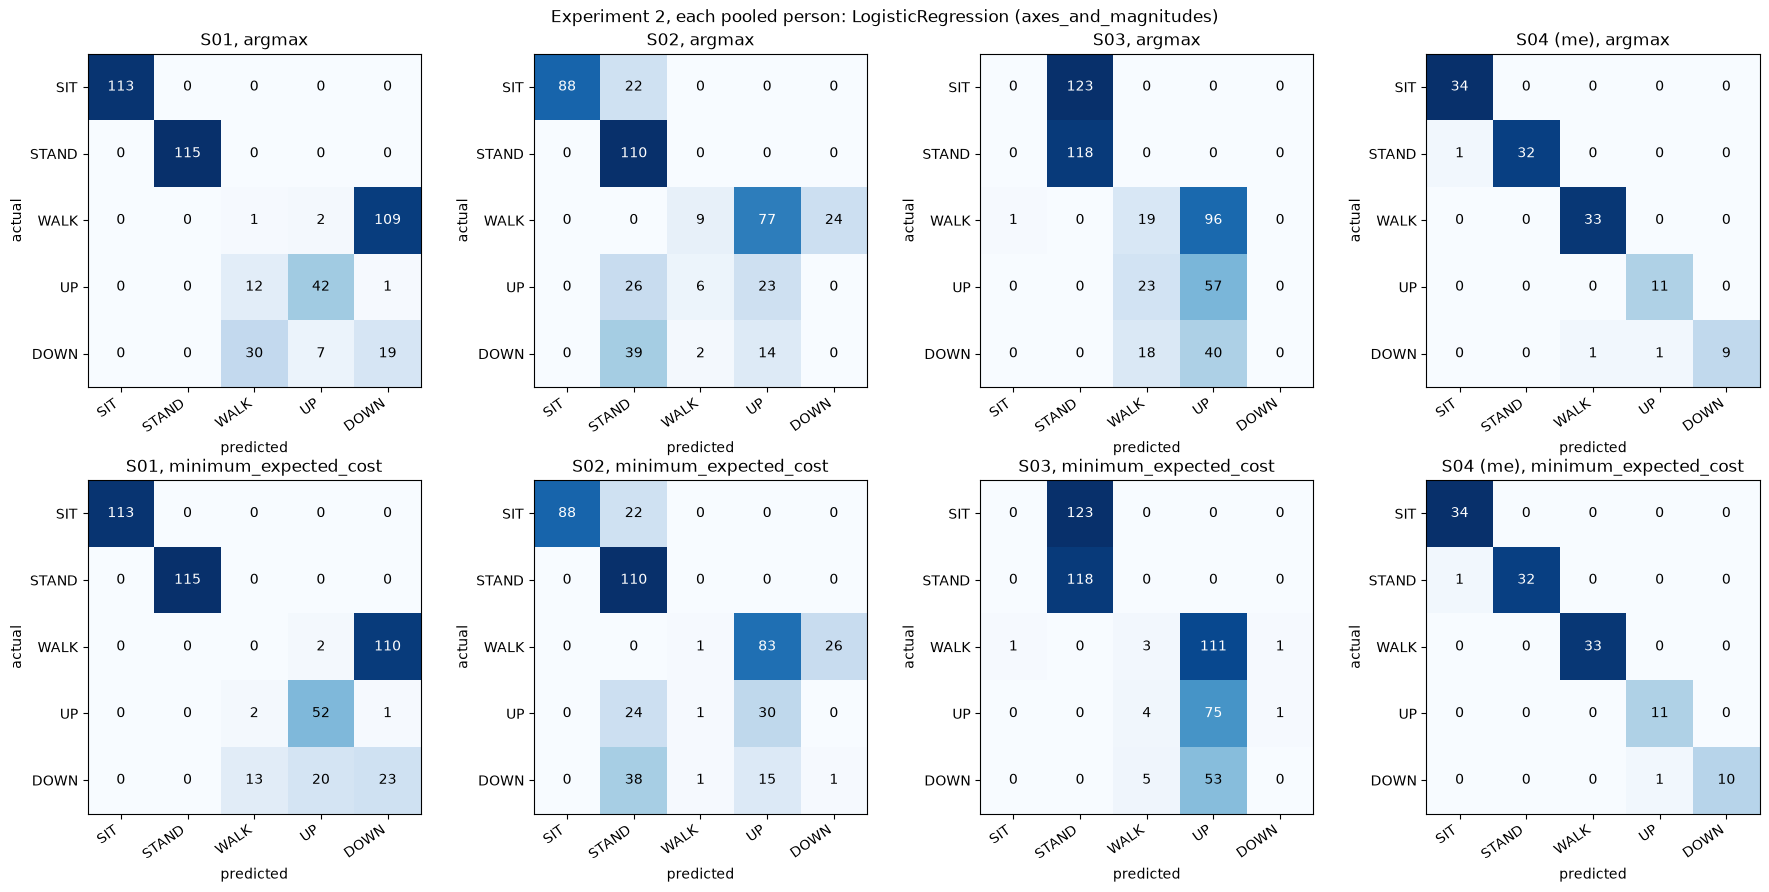

RandomForest: 2.0 s windows, 0% overlap, axes_and_magnitudes, {'max_depth': None, 'min_samples_leaf': 3, 'class_weight': 'balanced_subsample'}
validation macro F1 1.000


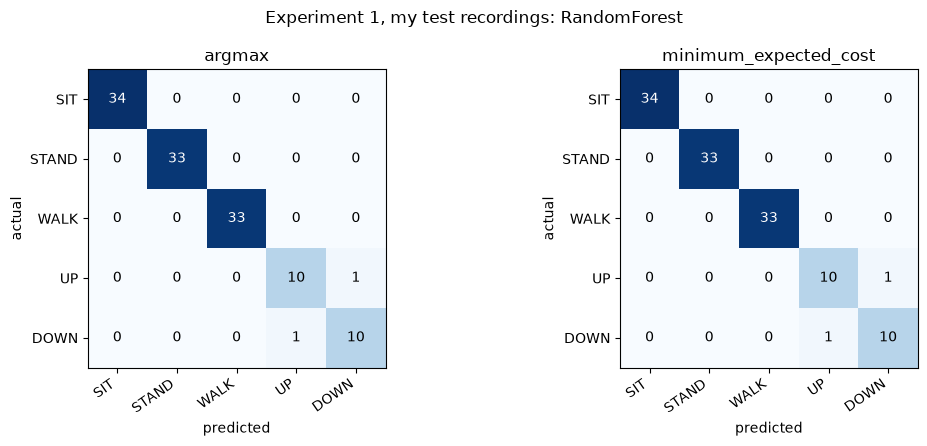

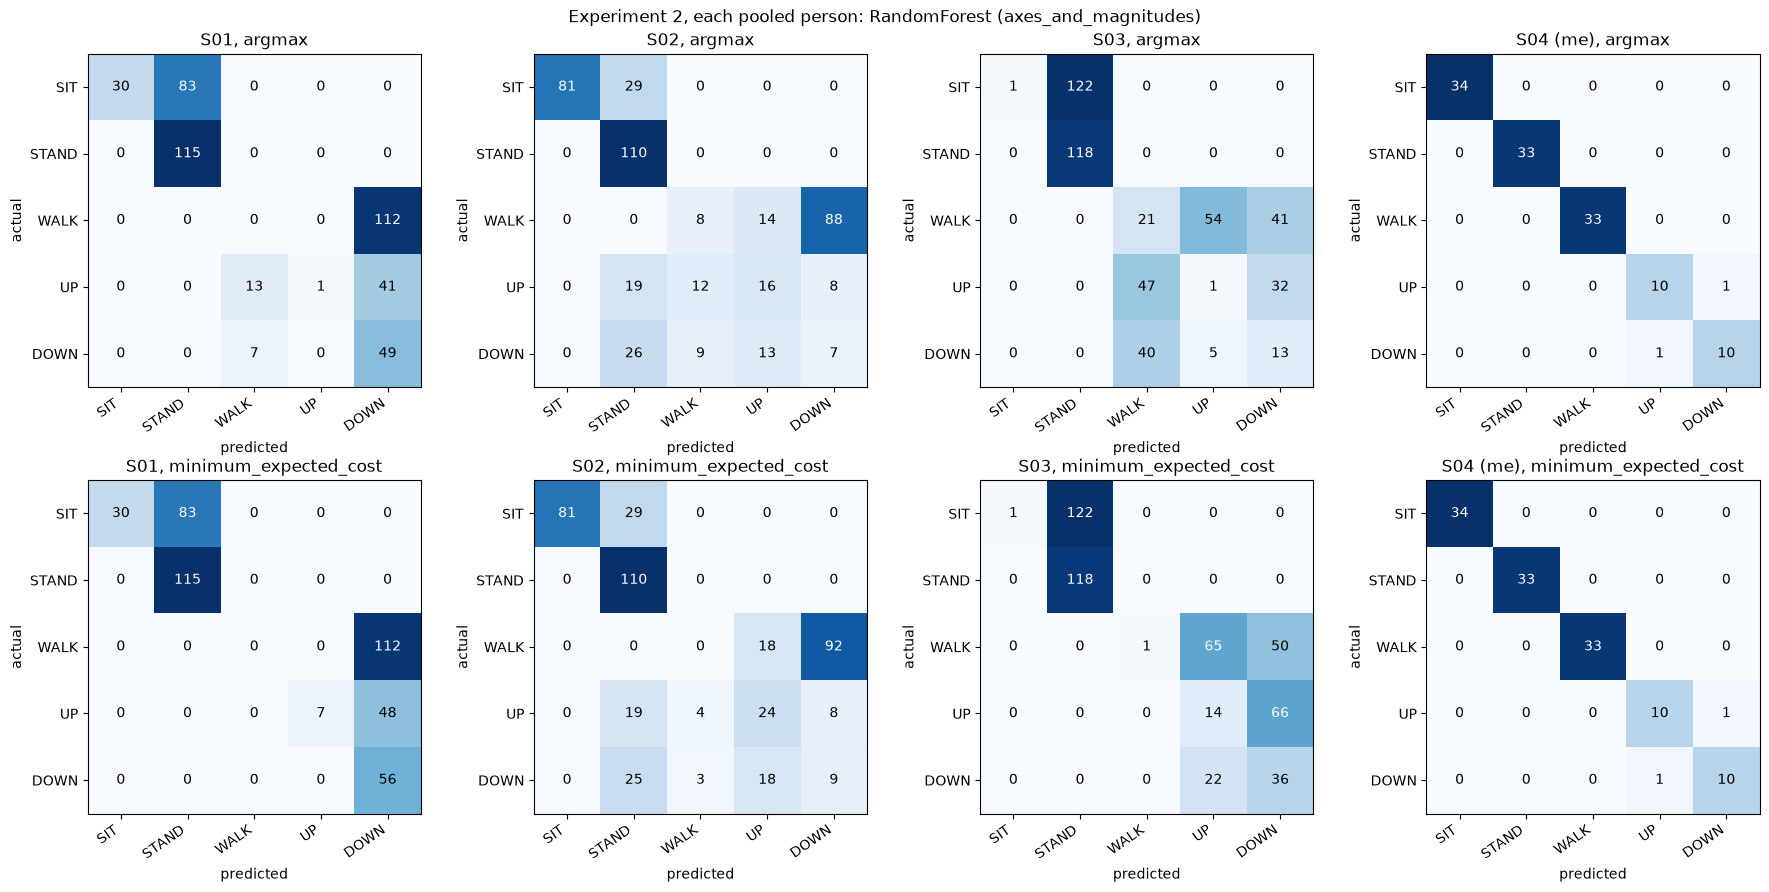

In [51]:
within_rows = []
tuning_rows = []
person_rows = []
confusion_rows = []
saved_models = {}
best_sets = {}
best_params = {}

pool = features[features.participant != "Dan"]

for name in ["LogisticRegression", "RandomForest"]:
    best, tried = find_best_config(name, train, validation)
    tuning_rows.extend(tried)

    length = best["window_seconds"]
    overlap = best["window_overlap"]
    print(f"{name}: {length} s windows, {overlap:.0%} overlap, {best['feature_set']}, {best['params']}")
    print(f"validation macro F1 {best['validation_macro_f1']:.3f}")

    fit_data = pd.concat([pick(train, length, overlap), pick(validation, length, overlap)], ignore_index=True)

    models = {}
    for set_name, cols in FEATURE_GROUPS.items():
        model = make_model(name, best["params"])
        model.fit(fit_data[cols], fit_data.label)
        models[set_name] = model

    model = models[best["feature_set"]]
    columns = FEATURE_GROUPS[best["feature_set"]]

    within_rows.extend(evaluate_within(name, model, columns, pick(test, length, overlap), best, confusion_rows))
    person_rows.extend(evaluate_across(name, models, pick(pool, length, overlap), best, self_person, confusion_rows))

    best_sets[name] = best["feature_set"]
    best_params[name] = best["params"]
    saved_models[name] = {"model": model, "feature_columns": columns,
                          "window_seconds": length, "window_overlap": overlap}

Save every table and the two chosen models (Section 8 loads them again).

In [52]:
import joblib

within = pd.DataFrame(within_rows)
across = pd.DataFrame(person_rows)
tuning = pd.DataFrame(tuning_rows)

within.to_csv(RESULTS / "within_person_metrics.csv", index=False)
across.to_csv(RESULTS / "across_person_metrics.csv", index=False)
tuning.to_csv(RESULTS / "validation_tuning_and_features.csv", index=False)
pd.DataFrame(confusion_rows).to_csv(RESULTS / "confusion_matrices.csv", index=False)
joblib.dump(saved_models, RESULTS / "trained_models.joblib")

['results\\trained_models.joblib']

Experiment 1 results on my test recordings.

In [53]:
score_columns = ["windows", "accuracy", "balanced_accuracy", "macro_f1", "expected_cost_per_1000"]
precision_columns = ["precision_SIT", "precision_STAND", "precision_WALK", "precision_UP", "precision_DOWN"]
recall_columns = ["recall_SIT", "recall_STAND", "recall_WALK", "recall_UP", "recall_DOWN"]

within[["model", "policy"] + score_columns].round(3)

,model,policy,windows,accuracy,balanced_accuracy,macro_f1,expected_cost_per_1000
0,LogisticRegression,argmax,122,0.975,0.958,0.962,106.557
1,LogisticRegression,minimum_expected_cost,122,0.984,0.976,0.976,24.590
2,RandomForest,argmax,122,0.984,0.964,0.964,32.787
3,RandomForest,minimum_expected_cost,122,0.984,0.964,0.964,32.787


Precision and recall for each activity on my test recordings.

In [54]:
within[["model", "policy"] + precision_columns + recall_columns].round(2)

,model,policy,precision_SIT,precision_STAND,precision_WALK,precision_UP,precision_DOWN,recall_SIT,recall_STAND,recall_WALK,recall_UP,recall_DOWN
0,LogisticRegression,argmax,0.97,1.0,0.97,0.92,1.00,1.0,0.97,1.0,1.00,0.82
1,LogisticRegression,minimum_expected_cost,0.97,1.0,1.00,0.92,1.00,1.0,0.97,1.0,1.00,0.91
2,RandomForest,argmax,1.00,1.0,1.00,0.91,0.91,1.0,1.00,1.0,0.91,0.91
3,RandomForest,minimum_expected_cost,1.00,1.0,1.00,0.91,0.91,1.0,1.00,1.0,0.91,0.91


Experiment 2 results for each pooled person, using the feature group each model chose.

In [55]:
chosen = across[across.feature_set == across.model.map(best_sets)]
chosen[["model", "person", "policy"] + score_columns].round(3)

,model,person,policy,windows,accuracy,balanced_accuracy,macro_f1,expected_cost_per_1000
0,LogisticRegression,S01,argmax,451,0.643,0.622,0.602,1705.100
1,LogisticRegression,S01,minimum_expected_cost,451,0.672,0.671,0.610,1170.732
6,LogisticRegression,S02,argmax,440,0.523,0.460,0.404,2461.364
7,LogisticRegression,S02,minimum_expected_cost,440,0.523,0.475,0.397,2315.909
12,LogisticRegression,S03,argmax,495,0.392,0.375,0.258,1822.222
13,LogisticRegression,S03,minimum_expected_cost,495,0.396,0.393,0.235,1329.293
18,LogisticRegression,S04,argmax,122,0.975,0.958,0.962,106.557
19,LogisticRegression,S04,minimum_expected_cost,122,0.984,0.976,0.976,24.590
24,RandomForest,S01,argmax,451,0.432,0.432,0.314,1554.324
25,RandomForest,S01,minimum_expected_cost,451,0.461,0.479,0.358,1141.907


Precision and recall for each activity and each pooled person.

In [56]:
chosen[["model", "person", "policy"] + precision_columns + recall_columns].round(2)

,model,person,policy,precision_SIT,precision_STAND,precision_WALK,precision_UP,precision_DOWN,recall_SIT,recall_STAND,recall_WALK,recall_UP,recall_DOWN
0,LogisticRegression,S01,argmax,1.00,1.00,0.02,0.82,0.15,1.00,1.00,0.01,0.76,0.34
1,LogisticRegression,S01,minimum_expected_cost,1.00,1.00,0.00,0.70,0.17,1.00,1.00,0.00,0.95,0.41
6,LogisticRegression,S02,argmax,1.00,0.56,0.53,0.20,0.00,0.80,1.00,0.08,0.42,0.00
7,LogisticRegression,S02,minimum_expected_cost,1.00,0.57,0.33,0.23,0.04,0.80,1.00,0.01,0.55,0.02
12,LogisticRegression,S03,argmax,0.00,0.49,0.32,0.30,0.00,0.00,1.00,0.16,0.71,0.00
13,LogisticRegression,S03,minimum_expected_cost,0.00,0.49,0.25,0.31,0.00,0.00,1.00,0.03,0.94,0.00
18,LogisticRegression,S04,argmax,0.97,1.00,0.97,0.92,1.00,1.00,0.97,1.00,1.00,0.82
19,LogisticRegression,S04,minimum_expected_cost,0.97,1.00,1.00,0.92,1.00,1.00,0.97,1.00,1.00,0.91
24,RandomForest,S01,argmax,1.00,0.58,0.00,1.00,0.24,0.27,1.00,0.00,0.02,0.88
25,RandomForest,S01,minimum_expected_cost,1.00,0.58,0.00,1.00,0.26,0.27,1.00,0.00,0.13,1.00


### 7.4 Which features are useful?

First, removing features and testing again. For each feature group: the best validation macro F1 on my data, and the average accuracy on the other people (argmax). The axes carry tilt, which may help for me but hurt on people whose phone sits differently.

In [57]:
unseen = across[(across.person != self_person) & (across.policy == "argmax")]

validation_score = tuning.groupby(["model", "feature_set"]).validation_macro_f1.max()
unseen_accuracy = unseen.groupby(["model", "feature_set"]).accuracy.mean()

ablation = pd.DataFrame({"best validation macro F1 (me)": validation_score,
                         "mean accuracy on unseen people": unseen_accuracy})
ablation.round(3)

best validation macro F1 (me)  \
model              feature_set                                          
LogisticRegression axes_and_magnitudes                          1.000   
                   axes_only                                    0.991   
                   magnitudes_only                              0.765   
RandomForest       axes_and_magnitudes                          1.000   
                   axes_only                                    1.000   
                   magnitudes_only                              0.930   

                                        mean accuracy on unseen people  
model              feature_set                                          
LogisticRegression axes_and_magnitudes                           0.519  
                   axes_only                                     0.550  
                   magnitudes_only                               0.332  
RandomForest       axes_and_magnitudes                           0.416  
                   axes_only                                     0.390  
                   magnitudes_only                               0.412

Second, the random forest's feature importances: how much each feature reduced Gini impurity, averaged over all the trees.

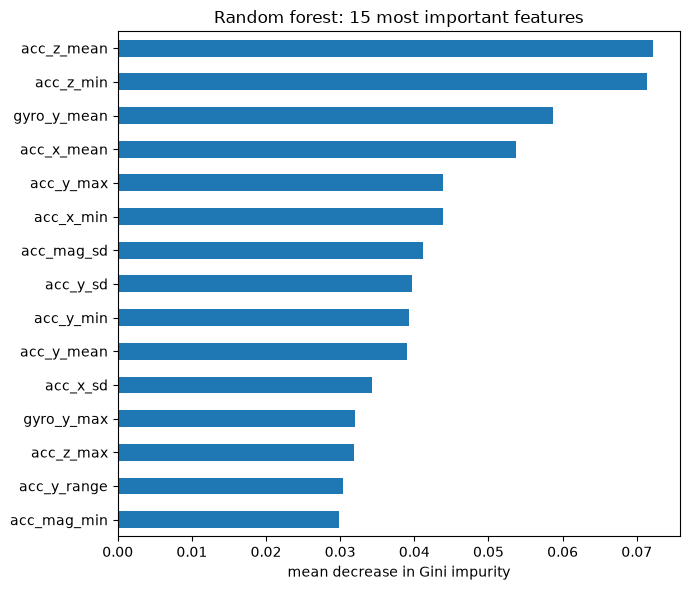

In [58]:
forest = saved_models["RandomForest"]
importances = pd.Series(forest["model"].feature_importances_, index=forest["feature_columns"])
importances = importances.sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
importances.tail(15).plot.barh(ax=ax)

ax.set_xlabel("mean decrease in Gini impurity")
ax.set_title("Random forest: 15 most important features")
plt.tight_layout()
plt.show()

## 8. Predicting a new recording

At the viva a new recording is classified with exactly the same steps: read, align, find runs, trim, cut into windows, and predict with both saved models and both decision rules. One row is saved for each window.

In [65]:
def predict_recording(zip_path, output_path=RESULTS / "predictions.csv"):
    saved = joblib.load(RESULTS / "trained_models.joblib")

    acc = read_sensor(zip_path, "Accelerometer")
    gyro = read_sensor(zip_path, "Gyroscope")
    aligned, _ = align_sensors(acc, gyro)
    if aligned.empty:
        raise ValueError("The recording has too few valid aligned sensor readings.")

    runs = find_runs(read_meta(zip_path, "time"), float(aligned.t.max()))
    info = {"participant": "unseen_person", "label": "UNLABELLED", "recording": Path(zip_path).name}

    configs = []
    for m in saved.values():
        config = (m["window_seconds"], m["window_overlap"])
        if config not in configs:
            configs.append(config)

    windows = pd.DataFrame(features_for_recording(aligned, runs, info, configs))
    if windows.empty:
        raise ValueError("No complete windows remain after cleaning and edge trimming.")

    keep = ["recording", "run", "window", "window_seconds", "window_overlap", "start", "end"]

    for name, m in saved.items():
        rows = (windows.window_seconds == m["window_seconds"]) & (windows.window_overlap == m["window_overlap"])
        for policy in POLICIES:
            column = name + "_" + policy
            windows.loc[rows, column] = predict(m["model"], windows[rows], m["feature_columns"], policy)
            keep.append(column)

    windows[keep].to_csv(output_path, index=False)
    print(len(windows), "windows saved to", output_path)
    return windows[keep]

Try it on any zip. The table counts how many windows each model gave to each activity.

In [72]:
predictions = predict_recording(Path("Unseen") / "DOWN_01.zip")

predictions.iloc[:, 7:].apply(pd.Series.value_counts).fillna(0).astype(int)

11 windows saved to results\predictions.csv


,LogisticRegression_argmax,LogisticRegression_minimum_expected_cost,RandomForest_argmax,RandomForest_minimum_expected_cost
DOWN,0,0,2,2
STAND,6,6,5,5
UP,5,5,3,4
WALK,0,0,1,0


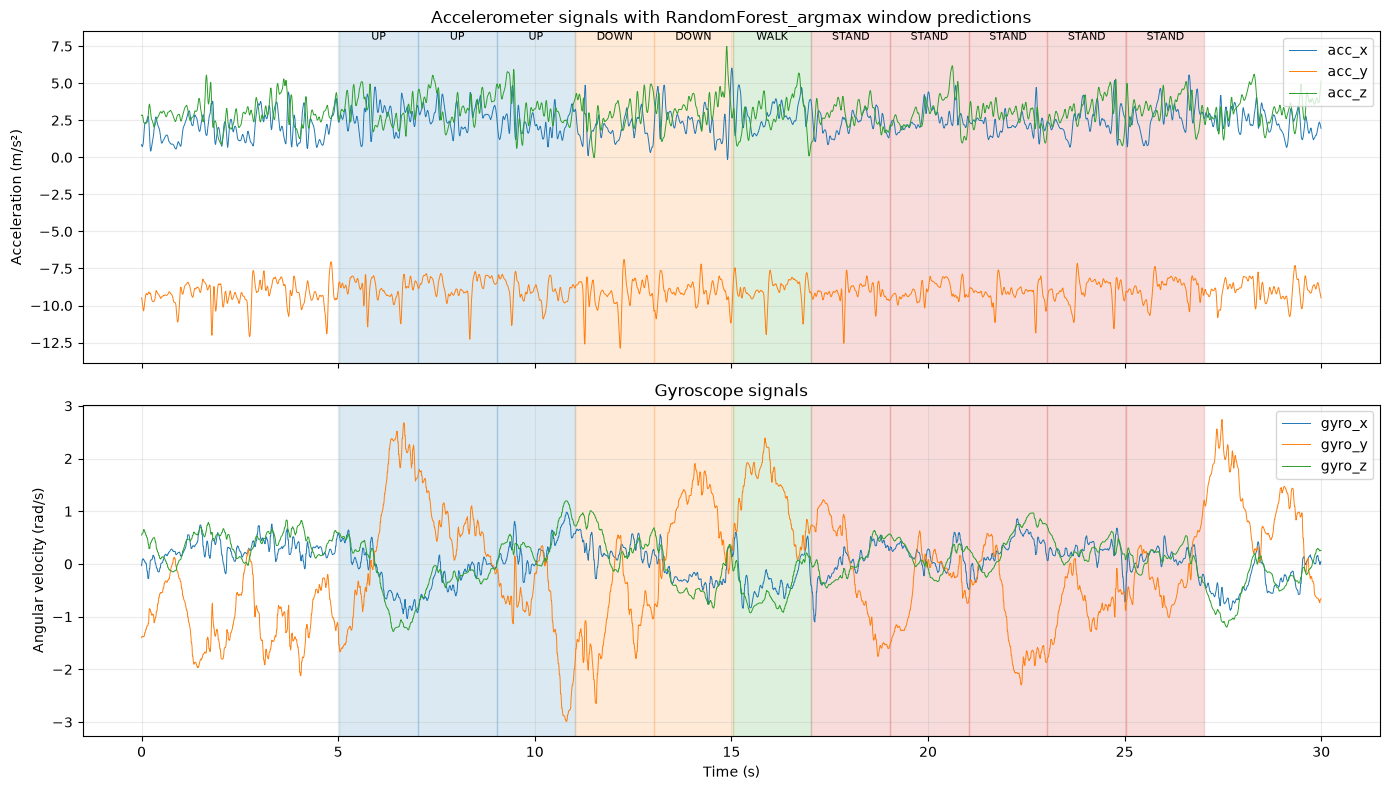

In [ ]:
# Select the model output to display
# prediction_column = "LogisticRegression_argmax"
# prediction_column = "LogisticRegression_minimum_expected_cost"
prediction_column = "RandomForest_argmax"
# prediction_column = "RandomForest_minimum_expected_cost"

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Plot the three accelerometer axes
for col in ["acc_x", "acc_y", "acc_z"]:
    axes[0].plot(aligned["t"], aligned[col], label=col, linewidth=0.7)
# Plot the three gyroscope axes
for col in ["gyro_x", "gyro_y", "gyro_z"]:
    axes[1].plot(aligned["t"], aligned[col], label=col, linewidth=0.7)

# Add a shaded region for each window and label it with its predicted activity
labels = predictions[prediction_column].dropna().unique()
colors = plt.get_cmap("tab10")

for i, (_, row) in enumerate(predictions.iterrows()):
    label = row[prediction_column]
    if pd.isna(label):
        continue

    color = colors(list(labels).index(label) % 10)

    for ax in axes:
        ax.axvspan(
            row["start"],
            row["end"],
            color=color,
            alpha=0.16
        )

    # Place the predicted activity label above the window
    axes[0].text(
        (row["start"] + row["end"]) / 2,
        axes[0].get_ylim()[1],
        str(label),
        ha="center",
        va="top",
        fontsize=8
    )

axes[0].set_title(f"Accelerometer signals with {prediction_column} window predictions")
axes[0].set_ylabel("Acceleration (m/s²)")
axes[1].set_title("Gyroscope signals")
axes[1].set_ylabel("Angular velocity (rad/s)")
axes[1].set_xlabel("Time (s)")

for ax in axes:
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()